In [1]:
from pathlib import Path
from typing import cast

import json

# pytorch
import torch
from torch import nn
from torch_geometric.data import Data

from dataset import add_stratified_masks, load_facebook_data
from modules import (
    GCNNetwork,
    GCNNetwork3Layer,
    GCNNetwork4Layer,
    GCNNetwork5Layer,
    GCNNetwork4LayerELU,
    GCNNetwork4LayerLReLU,
)

from train import (
    train_gcn_model,
    classification_metrics,
    plot_training_validation_loss,
    plot_training_validation_accuracy
)

# plotting
from matplotlib import pyplot as plt
import seaborn as sns

## Multi-Layer GNN for Facebook Page Classification
### COMP3710 Working Prototype Project in the Era of Artificial Intelligence
#### Derek McKinney (dm-uq)
#### SN: 45506053

### GCN Tuning
<br>
References:

Facebook Page-Page dataset:
    https://github.com/gayanku/facebook_page-page_dataset

PyG FacebookPagePage:
    https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.datasets.FacebookPagePage.html

Config and Constants

In [2]:
# constants
SEED = 808

# data parameters
TRAIN_PCT = 60
VAL_PCT = 20
TEST_PCT = 20

# GCN model parameters
HIDDEN_CHANNELS = 64
HIDDEN_CHANNELS_32 = 32
HIDDEN_CHANNELS_128 = 128
DROPOUT = 0.5
DROPOUT_03 = 0.3
DROPOUT_055 = 0.55
DROPOUT_06 = 0.6
DROPOUT_07 = 0.7

# loss function
CRITERION = nn.CrossEntropyLoss()

# hyper-parameters
LEARNING_RATE = 1e-3
LEARNING_RATE_5E4 = 5e-4
LEARNING_RATE_2E3 = 2e-3
LEARNING_RATE_1E4 = 1e-4
WEIGHT_DECAY = 0.0
WEIGHT_DECAY_5E5 = 5e-5
WEIGHT_DECAY_1E4 = 1e-4
WEIGHT_DECAY_5E4 = 5e-4
WEIGHT_DECAY_1E3 = 1e-3

EPOCHS_4K = 4000
EPOCHS_2K = 2000

# plot styling
sns.set_theme(
    context="notebook",
    style="whitegrid",
)

# output paths
RESULTS_DIR = Path("results")
CHECKPOINTS_DIR = Path("checkpoints")
FIGURES_DIR = Path("images/gcn")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Television show",
    "Government",
    "Company",
    "Politician",
]

In [3]:
# Device configuration
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Device: {device}")

if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Device: cuda
NVIDIA GeForce GTX 950M


Load the Facebook Graph

In [4]:
# load the FacebookPagePage dataset
dataset = load_facebook_data()
data = dataset[0]  # get first graph object

# create reproducible stratified train/validation/test splits
add_stratified_masks(
    cast(Data, data),
    train_pct=TRAIN_PCT,
    val_pct=VAL_PCT,
    test_pct=TEST_PCT,
    seed=SEED,
)

# load data onto the device
data = data.to(device)

### Depth Tuning

Ensure the Torch seed rng is reset

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 2-Layer 'Initial GCN' network

In [6]:
gcn2_model = GCNNetwork(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 2-Layer GCN

In [7]:
# optimiser
gcn2_optimizer = torch.optim.Adam(
    gcn2_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

#### Evaluate 2-Layer GCN Candidate

In [8]:
# perform training and validation of the 2-Layer 'Initial GCN'

gcn2_result = train_gcn_model(
    model=gcn2_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn2_optimizer,
    epochs=EPOCHS_4K,
    print_every=100,
)

> Training GCN
Epoch [   1/4000] Train Loss: 1.37681 | Val Loss: 1.36711 | Val Acc: 30.84%
Epoch [ 100/4000] Train Loss: 0.72976 | Val Loss: 0.71952 | Val Acc: 80.73%
Epoch [ 200/4000] Train Loss: 0.44348 | Val Loss: 0.43526 | Val Acc: 87.58%
Epoch [ 300/4000] Train Loss: 0.36085 | Val Loss: 0.35373 | Val Acc: 89.63%
Epoch [ 400/4000] Train Loss: 0.31590 | Val Loss: 0.31931 | Val Acc: 90.83%
Epoch [ 500/4000] Train Loss: 0.29588 | Val Loss: 0.30084 | Val Acc: 91.30%
Epoch [ 600/4000] Train Loss: 0.27696 | Val Loss: 0.28900 | Val Acc: 91.66%
Epoch [ 700/4000] Train Loss: 0.26783 | Val Loss: 0.28090 | Val Acc: 91.92%
Epoch [ 800/4000] Train Loss: 0.25678 | Val Loss: 0.27424 | Val Acc: 92.06%
Epoch [ 900/4000] Train Loss: 0.24410 | Val Loss: 0.26903 | Val Acc: 92.08%
Epoch [1000/4000] Train Loss: 0.23725 | Val Loss: 0.26406 | Val Acc: 92.21%
Epoch [1100/4000] Train Loss: 0.22887 | Val Loss: 0.25977 | Val Acc: 92.46%
Epoch [1200/4000] Train Loss: 0.22246 | Val Loss: 0.25612 | Val Acc: 92.5

Restore best result for 2-Layer GCN evaluation

In [9]:
# check that a best state exists
if gcn2_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn2_model.load_state_dict(
    gcn2_result["best_state"]
)

gcn2_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn2_logits = gcn2_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn2_metrics = classification_metrics(
    logits=gcn2_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 2-Layer GCN evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {gcn2_result['best_epoch']}\n"
    f"Validation loss: {gcn2_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn2_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn2_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn2_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn2_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn2_metrics['macro_auroc']:.4f}"
)

Best epoch:      3129
Validation loss: 0.22791
Accuracy:        0.9372
Macro precision: 0.9357
Macro recall:    0.9314
Macro F1:        0.9335
Macro AUROC:     0.9895


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn2_metrics['precision'][i]:.4f}  "
        f"R={gcn2_metrics['recall'][i]:.4f}  "
        f"F1={gcn2_metrics['f1'][i]:.4f}  "
        f"n={gcn2_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9322  R=0.9415  F1=0.9368  n=1299
Government       P=0.9408  R=0.9462  F1=0.9435  n=1376
Company          P=0.9465  R=0.9506  F1=0.9485  n=1153
Politician       P=0.9234  R=0.8874  F1=0.9051  n=666


Visualise Validation Loss for the 2-Layer GCN

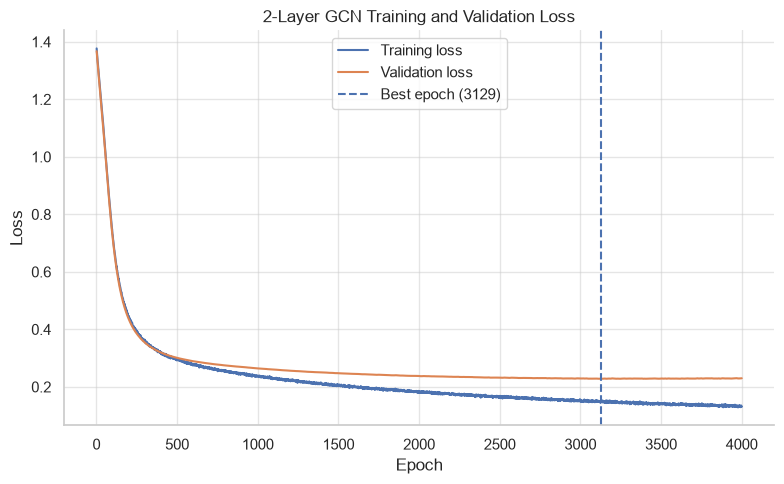

In [12]:
gcn2_loss_fig, _ = plot_training_validation_loss(
    history=gcn2_result["history"],
    best_epoch=gcn2_result["best_epoch"],
    title="2-Layer GCN Training and Validation Loss",
)

plt.show()

In [13]:
gcn2_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_depth_2layer_training_validation_loss_4000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 2-Layer GCN

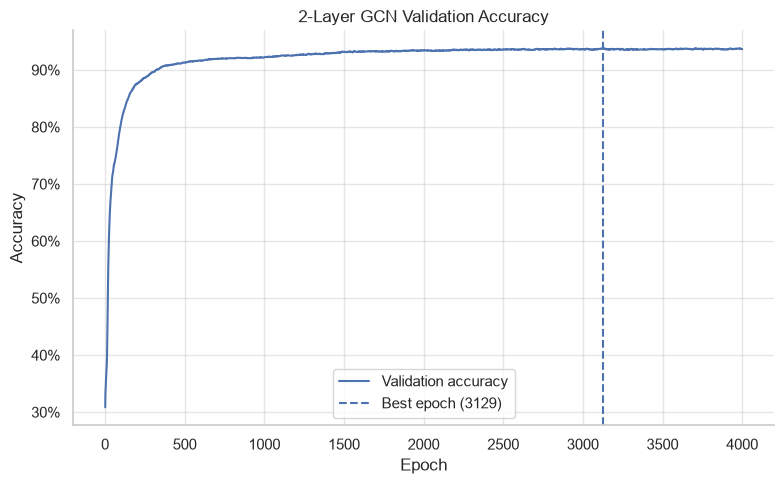

In [14]:
gcn2_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn2_result["history"],
    best_epoch=gcn2_result["best_epoch"],
    title="2-Layer GCN Validation Accuracy",
)

plt.show()

In [15]:
gcn2_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_depth_2layer_validation_accuracy_4000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 2-Layer GCN Candidate Results

In [16]:
# save 2-Layer GCN experiment results
gcn2_results = {
    "model": "GCN",
    "experiment": "depth",
    "num_layers": 2,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_4K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": gcn2_result["best_epoch"],
    "best_val_loss": gcn2_result["best_val_loss"],
    "training_seconds": gcn2_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn2_metrics,
    "history": gcn2_result["history"],
}

with (
    RESULTS_DIR / "gcn_depth_2layer.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn2_results,
        file,
        indent=2,
    )

torch.save(
    gcn2_result["best_state"],
    CHECKPOINTS_DIR / "gcn_depth_2layer.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 3-Layer 'Initial GCN' network

In [6]:
gcn3_model = GCNNetwork3Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 3-Layer GCN

In [7]:
# optimiser
gcn3_optimizer = torch.optim.Adam(
    gcn3_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

#### Evaluate 3-Layer GCN Candidate

In [8]:
# perform training and validation of the 3-Layer 'Initial GCN'

gcn3_result = train_gcn_model(
    model=gcn3_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn3_optimizer,
    epochs=EPOCHS_4K,
    print_every=100,
)

> Training GCN
Epoch [   1/4000] Train Loss: 1.40802 | Val Loss: 1.39932 | Val Acc: 19.27%
Epoch [ 100/4000] Train Loss: 0.44464 | Val Loss: 0.41700 | Val Acc: 87.96%
Epoch [ 200/4000] Train Loss: 0.28326 | Val Loss: 0.27592 | Val Acc: 91.81%
Epoch [ 300/4000] Train Loss: 0.25066 | Val Loss: 0.25459 | Val Acc: 92.59%
Epoch [ 400/4000] Train Loss: 0.22421 | Val Loss: 0.24407 | Val Acc: 93.10%
Epoch [ 500/4000] Train Loss: 0.21024 | Val Loss: 0.23560 | Val Acc: 93.50%
Epoch [ 600/4000] Train Loss: 0.19925 | Val Loss: 0.23043 | Val Acc: 93.64%
Epoch [ 700/4000] Train Loss: 0.18314 | Val Loss: 0.22494 | Val Acc: 93.97%
Epoch [ 800/4000] Train Loss: 0.17483 | Val Loss: 0.22177 | Val Acc: 94.01%
Epoch [ 900/4000] Train Loss: 0.16556 | Val Loss: 0.21822 | Val Acc: 94.19%
Epoch [1000/4000] Train Loss: 0.16293 | Val Loss: 0.21659 | Val Acc: 94.26%
Epoch [1100/4000] Train Loss: 0.15602 | Val Loss: 0.21431 | Val Acc: 94.37%
Epoch [1200/4000] Train Loss: 0.15028 | Val Loss: 0.21245 | Val Acc: 94.3

Restore best result for 3-Layer GCN evaluation

In [9]:
# check that a best state exists
if gcn3_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn3_model.load_state_dict(
    gcn3_result["best_state"]
)

gcn3_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn3_logits = gcn3_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn3_metrics = classification_metrics(
    logits=gcn3_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 3-Layer GCN evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {gcn3_result['best_epoch']}\n"
    f"Validation loss: {gcn3_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn3_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn3_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn3_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn3_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn3_metrics['macro_auroc']:.4f}"
)

Best epoch:      1517
Validation loss: 0.21073
Accuracy:        0.9470
Macro precision: 0.9462
Macro recall:    0.9417
Macro F1:        0.9438
Macro AUROC:     0.9906


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn3_metrics['precision'][i]:.4f}  "
        f"R={gcn3_metrics['recall'][i]:.4f}  "
        f"F1={gcn3_metrics['f1'][i]:.4f}  "
        f"n={gcn3_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9422  R=0.9530  F1=0.9476  n=1299
Government       P=0.9500  R=0.9535  F1=0.9518  n=1376
Company          P=0.9534  R=0.9592  F1=0.9563  n=1153
Politician       P=0.9390  R=0.9009  F1=0.9195  n=666


Visualise Validation Loss for the 3-Layer GCN

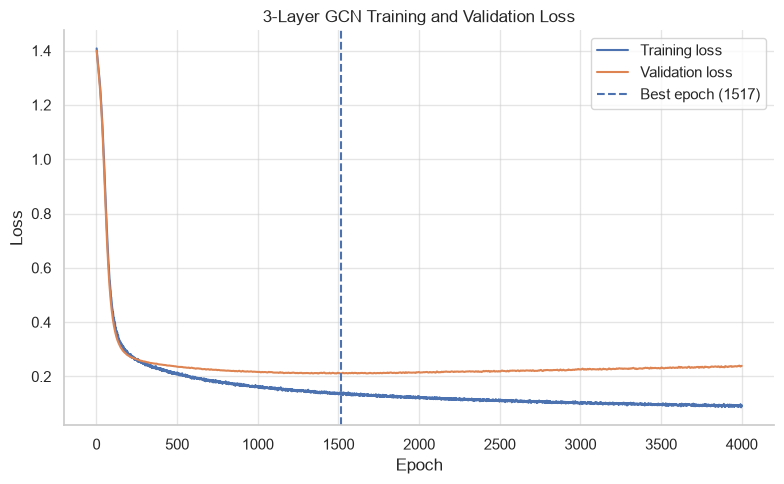

In [12]:
gcn3_loss_fig, _ = plot_training_validation_loss(
    history=gcn3_result["history"],
    best_epoch=gcn3_result["best_epoch"],
    title="3-Layer GCN Training and Validation Loss",
)

plt.show()

In [13]:
gcn3_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_depth_3layer_training_validation_loss_4000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 3-Layer GCN

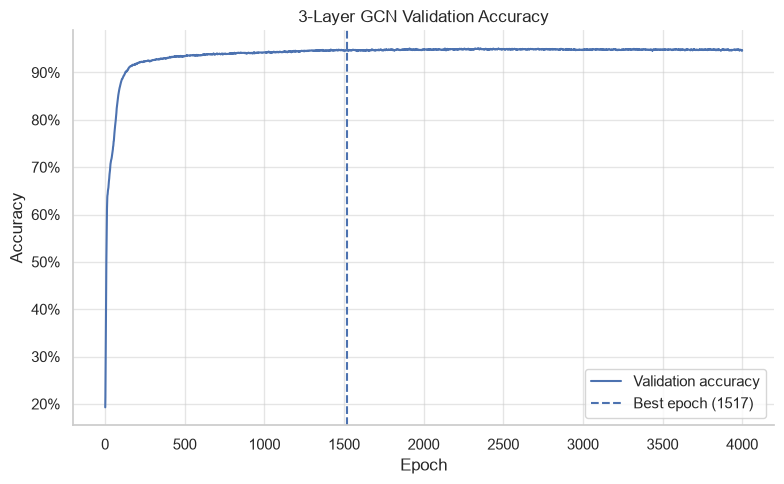

In [14]:
gcn3_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn3_result["history"],
    best_epoch=gcn3_result["best_epoch"],
    title="3-Layer GCN Validation Accuracy",
)

plt.show()

In [15]:
gcn3_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_depth_3layer_validation_accuracy_4000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 3-Layer GCN Candidate Results

In [17]:
# save 3-Layer GCN experiment results
gcn3_results = {
    "model": "GCN",
    "experiment": "depth",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_4K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": gcn3_result["best_epoch"],
    "best_val_loss": gcn3_result["best_val_loss"],
    "training_seconds": gcn3_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn3_metrics,
    "history": gcn3_result["history"],
}

with (
    RESULTS_DIR / "gcn_depth_3layer.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn3_results,
        file,
        indent=2,
    )

torch.save(
    gcn3_result["best_state"],
    CHECKPOINTS_DIR / "gcn_depth_3layer.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 4-Layer 'Initial GCN' network

In [6]:
gcn4_model = GCNNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN

In [7]:
# optimiser
gcn4_optimizer = torch.optim.Adam(
    gcn4_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

#### Evaluate 4-Layer GCN Candidate

In [8]:
# perform training and validation of the 4-Layer 'Initial GCN'

gcn4_result = train_gcn_model(
    model=gcn4_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn4_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training GCN
Epoch [   1/2000] Train Loss: 1.38770 | Val Loss: 1.38254 | Val Acc: 30.37%
Epoch [ 100/2000] Train Loss: 0.33152 | Val Loss: 0.30387 | Val Acc: 90.70%
Epoch [ 200/2000] Train Loss: 0.24319 | Val Loss: 0.24447 | Val Acc: 92.86%
Epoch [ 300/2000] Train Loss: 0.22109 | Val Loss: 0.23201 | Val Acc: 93.24%
Epoch [ 400/2000] Train Loss: 0.20043 | Val Loss: 0.22182 | Val Acc: 93.61%
Epoch [ 500/2000] Train Loss: 0.18543 | Val Loss: 0.21321 | Val Acc: 93.84%
Epoch [ 600/2000] Train Loss: 0.17379 | Val Loss: 0.20667 | Val Acc: 94.10%
Epoch [ 700/2000] Train Loss: 0.16470 | Val Loss: 0.20481 | Val Acc: 94.33%
Epoch [ 800/2000] Train Loss: 0.15429 | Val Loss: 0.20103 | Val Acc: 94.53%
Epoch [ 900/2000] Train Loss: 0.14780 | Val Loss: 0.19811 | Val Acc: 94.82%
Epoch [1000/2000] Train Loss: 0.14471 | Val Loss: 0.19750 | Val Acc: 94.68%
Epoch [1100/2000] Train Loss: 0.13885 | Val Loss: 0.19605 | Val Acc: 94.79%
Epoch [1200/2000] Train Loss: 0.13582 | Val Loss: 0.19307 | Val Acc: 95.1

Restore best result for 4-Layer GCN evaluation

In [9]:
# check that a best state exists
if gcn4_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn4_model.load_state_dict(
    gcn4_result["best_state"]
)

gcn4_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn4_logits = gcn4_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn4_metrics = classification_metrics(
    logits=gcn4_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 4-Layer GCN evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {gcn4_result['best_epoch']}\n"
    f"Validation loss: {gcn4_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn4_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn4_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn4_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn4_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn4_metrics['macro_auroc']:.4f}"
)

Best epoch:      1200
Validation loss: 0.19307
Accuracy:        0.9510
Macro precision: 0.9500
Macro recall:    0.9481
Macro F1:        0.9490
Macro AUROC:     0.9915


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn4_metrics['precision'][i]:.4f}  "
        f"R={gcn4_metrics['recall'][i]:.4f}  "
        f"F1={gcn4_metrics['f1'][i]:.4f}  "
        f"n={gcn4_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9536  R=0.9500  F1=0.9518  n=1299
Government       P=0.9481  R=0.9564  F1=0.9522  n=1376
Company          P=0.9576  R=0.9610  F1=0.9593  n=1153
Politician       P=0.9405  R=0.9249  F1=0.9326  n=666


Visualise Validation Loss for the 4-Layer GCN

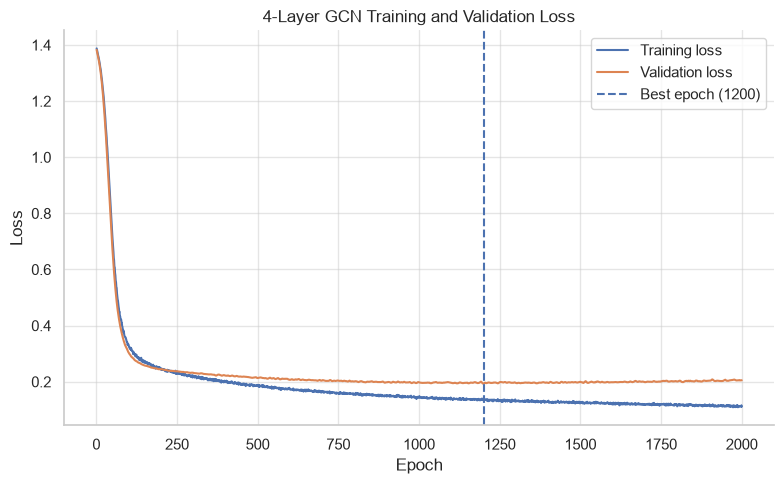

In [12]:
gcn4_loss_fig, _ = plot_training_validation_loss(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN Training and Validation Loss",
)

plt.show()

In [13]:
gcn4_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_depth_4layer_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 4-Layer GCN

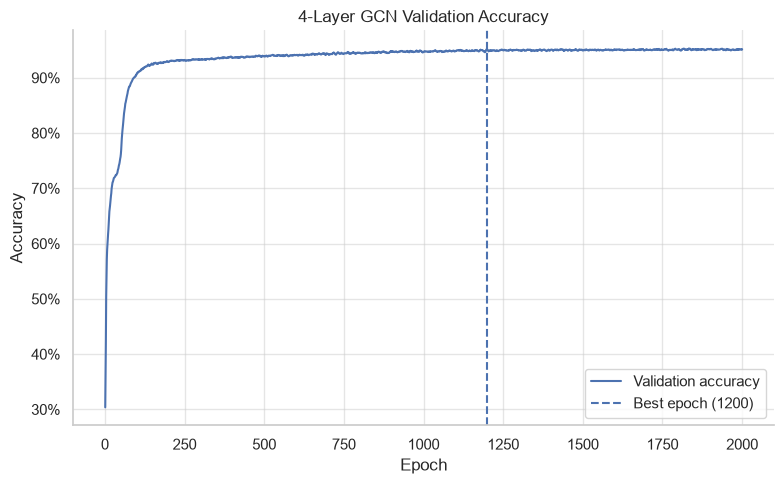

In [14]:
gcn4_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN Validation Accuracy",
)

plt.show()

In [15]:
gcn4_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_depth_4layer_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 4-Layer GCN Candidate Results

In [16]:
# save 4-Layer GCN experiment results
gcn4_results = {
    "model": "GCN",
    "experiment": "depth",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": gcn4_result["best_epoch"],
    "best_val_loss": gcn4_result["best_val_loss"],
    "training_seconds": gcn4_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn4_metrics,
    "history": gcn4_result["history"],
}

with (
    RESULTS_DIR / "gcn_depth_4layer.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_result["best_state"],
    CHECKPOINTS_DIR / "gcn_depth_4layer.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 5-Layer 'Initial GCN' network

In [6]:
gcn5_model = GCNNetwork5Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 5-Layer GCN

In [7]:
# optimiser
gcn5_optimizer = torch.optim.Adam(
    gcn5_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

#### Evaluate 5-Layer GCN Candidate

In [8]:
# perform training and validation of the 5-Layer 'Initial GCN'

gcn5_result = train_gcn_model(
    model=gcn5_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn5_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training GCN
Epoch [   1/2000] Train Loss: 1.38692 | Val Loss: 1.38025 | Val Acc: 30.69%
Epoch [ 100/2000] Train Loss: 0.31714 | Val Loss: 0.29112 | Val Acc: 91.54%
Epoch [ 200/2000] Train Loss: 0.23533 | Val Loss: 0.23467 | Val Acc: 93.28%
Epoch [ 300/2000] Train Loss: 0.21877 | Val Loss: 0.22137 | Val Acc: 93.59%
Epoch [ 400/2000] Train Loss: 0.19693 | Val Loss: 0.21247 | Val Acc: 94.06%
Epoch [ 500/2000] Train Loss: 0.18023 | Val Loss: 0.21198 | Val Acc: 94.21%
Epoch [ 600/2000] Train Loss: 0.17247 | Val Loss: 0.20591 | Val Acc: 94.41%
Epoch [ 700/2000] Train Loss: 0.16493 | Val Loss: 0.20190 | Val Acc: 94.84%
Epoch [ 800/2000] Train Loss: 0.16329 | Val Loss: 0.19913 | Val Acc: 94.86%
Epoch [ 900/2000] Train Loss: 0.15040 | Val Loss: 0.19866 | Val Acc: 94.93%
Epoch [1000/2000] Train Loss: 0.14874 | Val Loss: 0.20062 | Val Acc: 94.88%
Epoch [1100/2000] Train Loss: 0.14027 | Val Loss: 0.19671 | Val Acc: 94.90%
Epoch [1200/2000] Train Loss: 0.13882 | Val Loss: 0.19972 | Val Acc: 94.8

Restore best result for 5-Layer GCN evaluation

In [9]:
# check that a best state exists
if gcn5_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn5_model.load_state_dict(
    gcn5_result["best_state"]
)

gcn5_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn5_logits = gcn5_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn5_metrics = classification_metrics(
    logits=gcn5_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 5-Layer GCN evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {gcn5_result['best_epoch']}\n"
    f"Validation loss: {gcn5_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn5_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn5_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn5_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn5_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn5_metrics['macro_auroc']:.4f}"
)

Best epoch:      890
Validation loss: 0.19496
Accuracy:        0.9490
Macro precision: 0.9484
Macro recall:    0.9455
Macro F1:        0.9469
Macro AUROC:     0.9910


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn5_metrics['precision'][i]:.4f}  "
        f"R={gcn5_metrics['recall'][i]:.4f}  "
        f"F1={gcn5_metrics['f1'][i]:.4f}  "
        f"n={gcn5_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9521  R=0.9492  F1=0.9507  n=1299
Government       P=0.9466  R=0.9528  F1=0.9497  n=1376
Company          P=0.9520  R=0.9627  F1=0.9573  n=1153
Politician       P=0.9429  R=0.9174  F1=0.9300  n=666


Visualise Validation Loss for the 5-Layer GCN

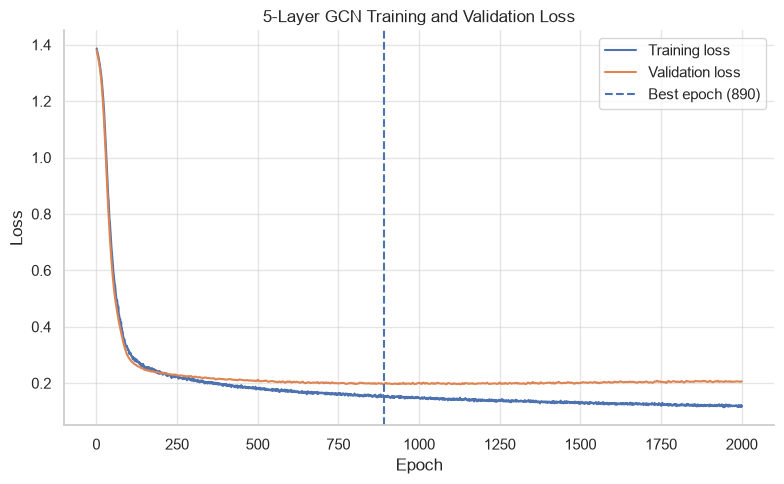

In [12]:
gcn5_loss_fig, _ = plot_training_validation_loss(
    history=gcn5_result["history"],
    best_epoch=gcn5_result["best_epoch"],
    title="5-Layer GCN Training and Validation Loss",
)

plt.show()

In [13]:
gcn5_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_depth_5layer_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 5-Layer GCN

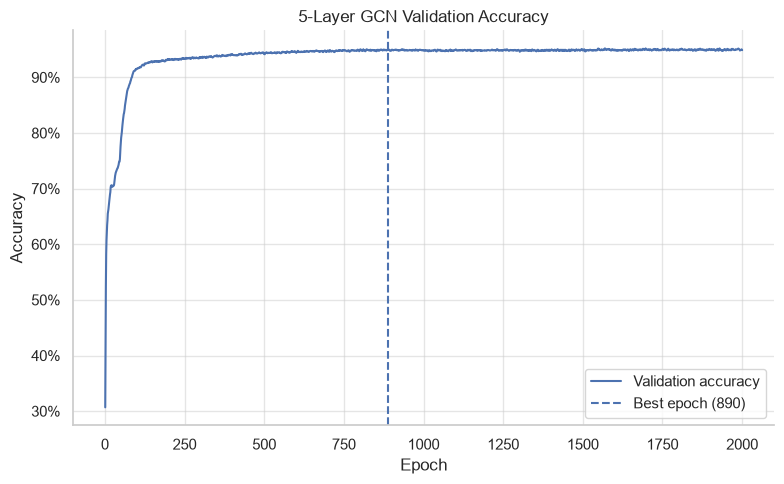

In [14]:
gcn5_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn5_result["history"],
    best_epoch=gcn5_result["best_epoch"],
    title="5-Layer GCN Validation Accuracy",
)

plt.show()

In [15]:
gcn5_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_depth_5layer_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 5-Layer GCN Candidate Results

In [16]:
# save 5-Layer GCN experiment results
gcn5_results = {
    "model": "GCN",
    "experiment": "depth",
    "num_layers": 5,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": gcn5_result["best_epoch"],
    "best_val_loss": gcn5_result["best_val_loss"],
    "training_seconds": gcn5_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn5_metrics,
    "history": gcn5_result["history"],
}

with (
    RESULTS_DIR / "gcn_depth_5layer.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn5_results,
        file,
        indent=2,
    )

torch.save(
    gcn5_result["best_state"],
    CHECKPOINTS_DIR / "gcn_depth_5layer.pt",
)

The 4-layer GCN performed best on every aggregate validation measure.<br>
Every class attains its highest F1 at four layers.<br>
The 4-layer GCN provides the best precision–recall balance for every individual class.

### Dropout Tuning

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 4-Layer GCN (dropout=0.3) network

In [6]:
gcn4_model = GCNNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_03,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN (dropout=0.3)

In [7]:
# optimiser
gcn4_optimizer = torch.optim.Adam(
    gcn4_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

#### Evaluate 4-Layer GCN (dropout=0.3) Candidate

In [8]:
# perform training and validation of the 4-Layer GCN (dropout=0.3)

gcn4_result = train_gcn_model(
    model=gcn4_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn4_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training GCN
Epoch [   1/2000] Train Loss: 1.38809 | Val Loss: 1.38241 | Val Acc: 30.22%
Epoch [ 100/2000] Train Loss: 0.30650 | Val Loss: 0.29581 | Val Acc: 91.01%
Epoch [ 200/2000] Train Loss: 0.22596 | Val Loss: 0.24104 | Val Acc: 92.95%
Epoch [ 300/2000] Train Loss: 0.20006 | Val Loss: 0.22768 | Val Acc: 93.37%
Epoch [ 400/2000] Train Loss: 0.18115 | Val Loss: 0.21856 | Val Acc: 93.75%
Epoch [ 500/2000] Train Loss: 0.16698 | Val Loss: 0.21232 | Val Acc: 94.08%
Epoch [ 600/2000] Train Loss: 0.15220 | Val Loss: 0.20625 | Val Acc: 94.37%
Epoch [ 700/2000] Train Loss: 0.14348 | Val Loss: 0.20545 | Val Acc: 94.44%
Epoch [ 800/2000] Train Loss: 0.13608 | Val Loss: 0.20098 | Val Acc: 94.66%
Epoch [ 900/2000] Train Loss: 0.13021 | Val Loss: 0.20135 | Val Acc: 94.75%
Epoch [1000/2000] Train Loss: 0.12549 | Val Loss: 0.20360 | Val Acc: 94.82%
Epoch [1100/2000] Train Loss: 0.11964 | Val Loss: 0.20231 | Val Acc: 94.93%
Epoch [1200/2000] Train Loss: 0.11565 | Val Loss: 0.20167 | Val Acc: 95.0

Restore best result for 4-Layer GCN (dropout=0.3) evaluation

In [9]:
# check that a best state exists
if gcn4_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn4_model.load_state_dict(
    gcn4_result["best_state"]
)

gcn4_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn4_logits = gcn4_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn4_metrics = classification_metrics(
    logits=gcn4_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 4-Layer GCN (dropout=0.3) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {gcn4_result['best_epoch']}\n"
    f"Validation loss: {gcn4_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn4_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn4_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn4_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn4_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn4_metrics['macro_auroc']:.4f}"
)

Best epoch:      990
Validation loss: 0.19880
Accuracy:        0.9482
Macro precision: 0.9471
Macro recall:    0.9443
Macro F1:        0.9457
Macro AUROC:     0.9911


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn4_metrics['precision'][i]:.4f}  "
        f"R={gcn4_metrics['recall'][i]:.4f}  "
        f"F1={gcn4_metrics['f1'][i]:.4f}  "
        f"n={gcn4_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9487  R=0.9538  F1=0.9512  n=1299
Government       P=0.9499  R=0.9499  F1=0.9499  n=1376
Company          P=0.9502  R=0.9592  F1=0.9547  n=1153
Politician       P=0.9398  R=0.9144  F1=0.9269  n=666


Visualise Validation Loss for the 4-Layer GCN (dropout=0.3)

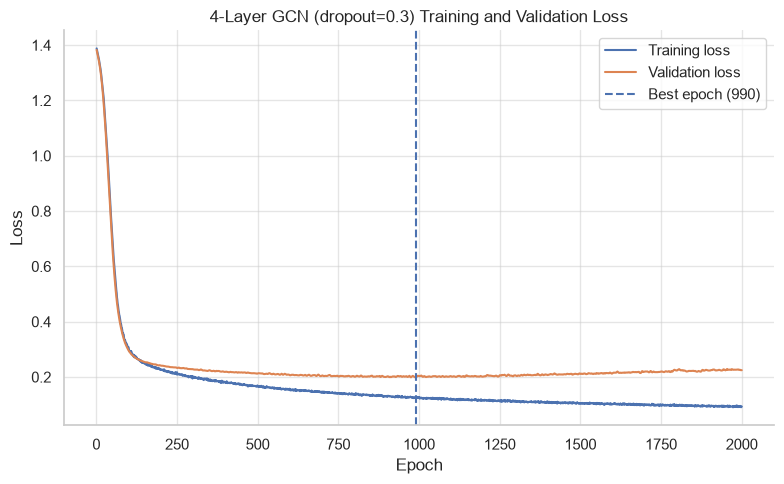

In [12]:
gcn4_loss_fig, _ = plot_training_validation_loss(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (dropout=0.3) Training and Validation Loss",
)

plt.show()

In [13]:
gcn4_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_dropout_030_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 4-Layer GCN (dropout=0.3)

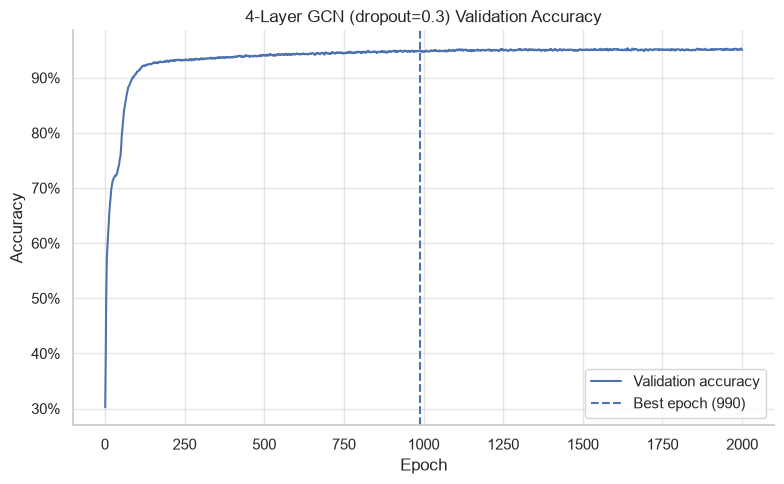

In [14]:
gcn4_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (dropout=0.3) Validation Accuracy",
)

plt.show()

In [15]:
gcn4_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_dropout_030_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 4-Layer GCN (dropout=0.3) Candidate Results

In [16]:
# save 4-Layer GCN (dropout=0.3) experiment results
gcn4_results = {
    "model": "GCN",
    "experiment": "dropout",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_03,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": gcn4_result["best_epoch"],
    "best_val_loss": gcn4_result["best_val_loss"],
    "training_seconds": gcn4_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn4_metrics,
    "history": gcn4_result["history"],
}

with (
    RESULTS_DIR / "gcn_dropout_030.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_result["best_state"],
    CHECKPOINTS_DIR / "gcn_dropout_030.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 4-Layer GCN (dropout=0.55) network

In [6]:
gcn4_model = GCNNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_055,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN (dropout=0.55)

In [7]:
# optimiser
gcn4_optimizer = torch.optim.Adam(
    gcn4_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

#### Evaluate 4-Layer GCN (dropout=0.55) Candidate

In [8]:
# perform training and validation of the 4-Layer GCN (dropout=0.55)

gcn4_result = train_gcn_model(
    model=gcn4_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn4_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training GCN
Epoch [   1/2000] Train Loss: 1.38753 | Val Loss: 1.38258 | Val Acc: 29.93%
Epoch [ 100/2000] Train Loss: 0.34215 | Val Loss: 0.30698 | Val Acc: 90.54%
Epoch [ 200/2000] Train Loss: 0.24653 | Val Loss: 0.24537 | Val Acc: 92.81%
Epoch [ 300/2000] Train Loss: 0.22928 | Val Loss: 0.23307 | Val Acc: 93.24%
Epoch [ 400/2000] Train Loss: 0.20679 | Val Loss: 0.22242 | Val Acc: 93.75%
Epoch [ 500/2000] Train Loss: 0.19152 | Val Loss: 0.21395 | Val Acc: 93.84%
Epoch [ 600/2000] Train Loss: 0.17926 | Val Loss: 0.20715 | Val Acc: 94.15%
Epoch [ 700/2000] Train Loss: 0.17208 | Val Loss: 0.20418 | Val Acc: 94.24%
Epoch [ 800/2000] Train Loss: 0.16286 | Val Loss: 0.20039 | Val Acc: 94.35%
Epoch [ 900/2000] Train Loss: 0.15581 | Val Loss: 0.19683 | Val Acc: 94.68%
Epoch [1000/2000] Train Loss: 0.15290 | Val Loss: 0.19748 | Val Acc: 94.62%
Epoch [1100/2000] Train Loss: 0.14592 | Val Loss: 0.19594 | Val Acc: 94.73%
Epoch [1200/2000] Train Loss: 0.14219 | Val Loss: 0.19314 | Val Acc: 95.0

Restore best result for 4-Layer GCN (dropout=0.55) evaluation

In [9]:
# check that a best state exists
if gcn4_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn4_model.load_state_dict(
    gcn4_result["best_state"]
)

gcn4_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn4_logits = gcn4_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn4_metrics = classification_metrics(
    logits=gcn4_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 4-Layer GCN (dropout=0.55) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {gcn4_result['best_epoch']}\n"
    f"Validation loss: {gcn4_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn4_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn4_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn4_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn4_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn4_metrics['macro_auroc']:.4f}"
)

Best epoch:      1367
Validation loss: 0.19226
Accuracy:        0.9504
Macro precision: 0.9493
Macro recall:    0.9470
Macro F1:        0.9481
Macro AUROC:     0.9916


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn4_metrics['precision'][i]:.4f}  "
        f"R={gcn4_metrics['recall'][i]:.4f}  "
        f"F1={gcn4_metrics['f1'][i]:.4f}  "
        f"n={gcn4_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9516  R=0.9530  F1=0.9523  n=1299
Government       P=0.9493  R=0.9535  F1=0.9514  n=1376
Company          P=0.9560  R=0.9610  F1=0.9585  n=1153
Politician       P=0.9402  R=0.9204  F1=0.9302  n=666


Visualise Validation Loss for the 4-Layer GCN (dropout=0.55)

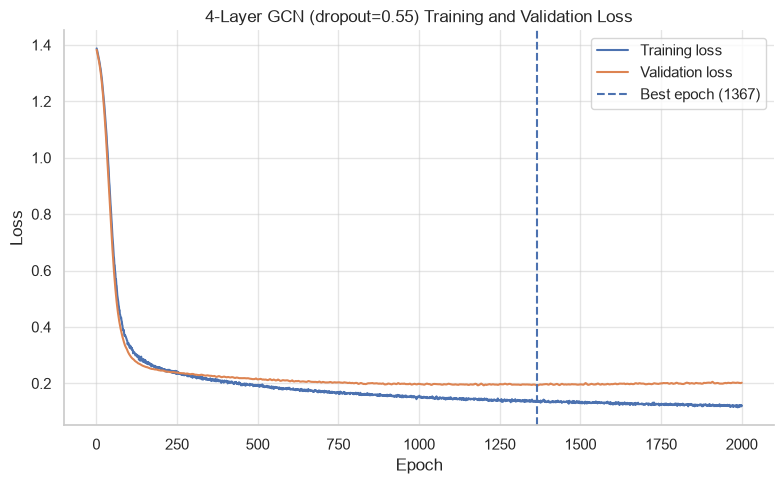

In [12]:
gcn4_loss_fig, _ = plot_training_validation_loss(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (dropout=0.55) Training and Validation Loss",
)

plt.show()

In [13]:
gcn4_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_dropout_055_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 4-Layer GCN (dropout=0.55)

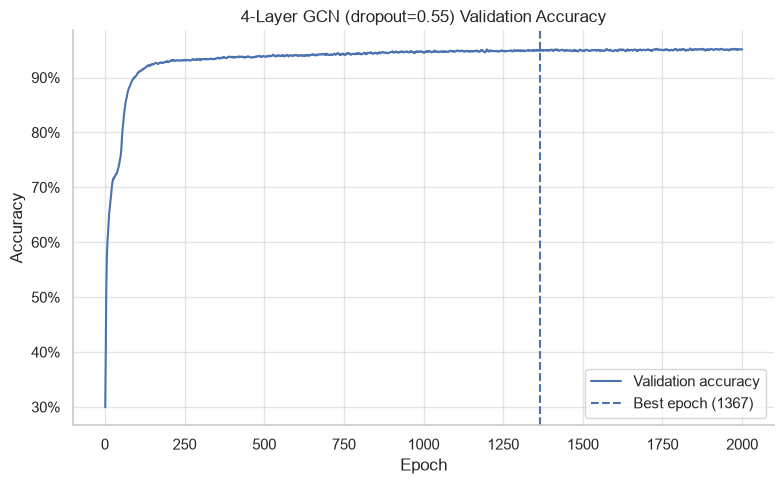

In [14]:
gcn4_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (dropout=0.55) Validation Accuracy",
)

plt.show()

In [15]:
gcn4_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_dropout_055_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 4-Layer GCN (dropout=0.55) Candidate Results

In [16]:
# save 4-Layer GCN (dropout=0.55) experiment results
gcn4_results = {
    "model": "GCN",
    "experiment": "dropout",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_055,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": gcn4_result["best_epoch"],
    "best_val_loss": gcn4_result["best_val_loss"],
    "training_seconds": gcn4_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn4_metrics,
    "history": gcn4_result["history"],
}

with (
    RESULTS_DIR / "gcn_dropout_055.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_result["best_state"],
    CHECKPOINTS_DIR / "gcn_dropout_055.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 4-Layer GCN (dropout=0.6) network

In [6]:
gcn4_model = GCNNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_06,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN (dropout=0.6)

In [7]:
# optimiser
gcn4_optimizer = torch.optim.Adam(
    gcn4_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

#### Evaluate 4-Layer GCN (dropout=0.6) Candidate

In [8]:
# perform training and validation of the 4-Layer GCN (dropout=0.6)

gcn4_result = train_gcn_model(
    model=gcn4_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn4_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training GCN
Epoch [   1/2000] Train Loss: 1.38796 | Val Loss: 1.38265 | Val Acc: 29.86%
Epoch [ 100/2000] Train Loss: 0.34990 | Val Loss: 0.30979 | Val Acc: 90.50%
Epoch [ 200/2000] Train Loss: 0.25182 | Val Loss: 0.24658 | Val Acc: 92.77%
Epoch [ 300/2000] Train Loss: 0.23563 | Val Loss: 0.23376 | Val Acc: 93.32%
Epoch [ 400/2000] Train Loss: 0.21556 | Val Loss: 0.22343 | Val Acc: 93.70%
Epoch [ 500/2000] Train Loss: 0.19809 | Val Loss: 0.21483 | Val Acc: 93.64%
Epoch [ 600/2000] Train Loss: 0.18493 | Val Loss: 0.20751 | Val Acc: 94.06%
Epoch [ 700/2000] Train Loss: 0.17811 | Val Loss: 0.20420 | Val Acc: 94.17%
Epoch [ 800/2000] Train Loss: 0.17144 | Val Loss: 0.20113 | Val Acc: 94.39%
Epoch [ 900/2000] Train Loss: 0.16236 | Val Loss: 0.19654 | Val Acc: 94.59%
Epoch [1000/2000] Train Loss: 0.15949 | Val Loss: 0.19706 | Val Acc: 94.44%
Epoch [1100/2000] Train Loss: 0.15322 | Val Loss: 0.19614 | Val Acc: 94.66%
Epoch [1200/2000] Train Loss: 0.14962 | Val Loss: 0.19321 | Val Acc: 94.7

Restore best result for 4-Layer GCN (dropout=0.6) evaluation

In [9]:
# check that a best state exists
if gcn4_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn4_model.load_state_dict(
    gcn4_result["best_state"]
)

gcn4_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn4_logits = gcn4_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn4_metrics = classification_metrics(
    logits=gcn4_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 4-Layer GCN (dropout=0.6) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {gcn4_result['best_epoch']}\n"
    f"Validation loss: {gcn4_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn4_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn4_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn4_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn4_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn4_metrics['macro_auroc']:.4f}"
)

Best epoch:      1367
Validation loss: 0.19123
Accuracy:        0.9482
Macro precision: 0.9469
Macro recall:    0.9439
Macro F1:        0.9454
Macro AUROC:     0.9916


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn4_metrics['precision'][i]:.4f}  "
        f"R={gcn4_metrics['recall'][i]:.4f}  "
        f"F1={gcn4_metrics['f1'][i]:.4f}  "
        f"n={gcn4_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9457  R=0.9515  F1=0.9486  n=1299
Government       P=0.9493  R=0.9535  F1=0.9514  n=1376
Company          P=0.9559  R=0.9592  F1=0.9576  n=1153
Politician       P=0.9367  R=0.9114  F1=0.9239  n=666


Visualise Validation Loss for the 4-Layer GCN (dropout=0.6)

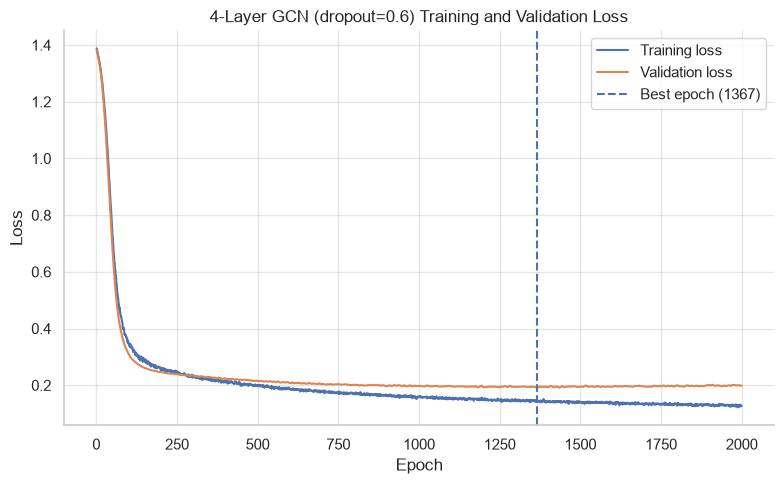

In [12]:
gcn4_loss_fig, _ = plot_training_validation_loss(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (dropout=0.6) Training and Validation Loss",
)

plt.show()

In [13]:
gcn4_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_dropout_060_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 4-Layer GCN (dropout=0.6)

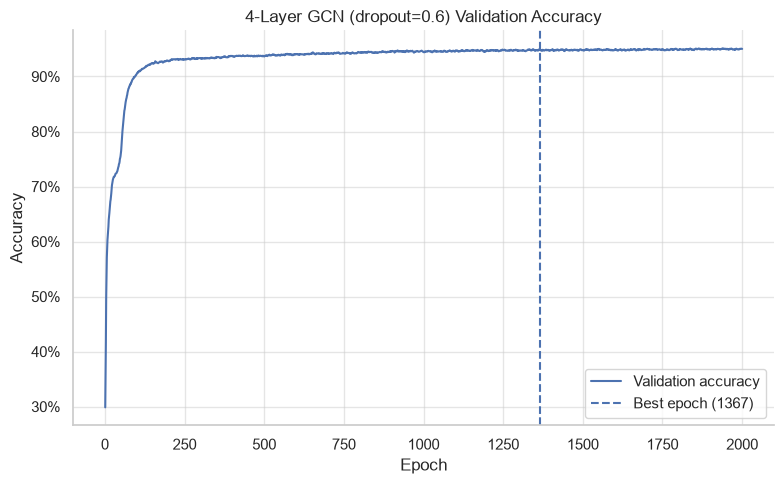

In [14]:
gcn4_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (dropout=0.6) Validation Accuracy",
)

plt.show()

In [15]:
gcn4_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_dropout_060_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 4-Layer GCN (dropout=0.6) Candidate Results

In [16]:
# save 4-Layer GCN (dropout=0.6) experiment results
gcn4_results = {
    "model": "GCN",
    "experiment": "dropout",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_06,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": gcn4_result["best_epoch"],
    "best_val_loss": gcn4_result["best_val_loss"],
    "training_seconds": gcn4_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn4_metrics,
    "history": gcn4_result["history"],
}

with (
    RESULTS_DIR / "gcn_dropout_060.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_result["best_state"],
    CHECKPOINTS_DIR / "gcn_dropout_060.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 4-Layer GCN (dropout=0.7) network

In [6]:
gcn4_model = GCNNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_07,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN (dropout=0.7)

In [7]:
# optimiser
gcn4_optimizer = torch.optim.Adam(
    gcn4_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

#### Evaluate 4-Layer GCN (dropout=0.7) Candidate

In [8]:
# perform training and validation of the 4-Layer GCN (dropout=0.7)

gcn4_result = train_gcn_model(
    model=gcn4_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn4_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training GCN
Epoch [   1/2000] Train Loss: 1.38924 | Val Loss: 1.38280 | Val Acc: 29.88%
Epoch [ 100/2000] Train Loss: 0.38375 | Val Loss: 0.32092 | Val Acc: 90.12%
Epoch [ 200/2000] Train Loss: 0.26904 | Val Loss: 0.25021 | Val Acc: 92.81%
Epoch [ 300/2000] Train Loss: 0.26079 | Val Loss: 0.23638 | Val Acc: 93.24%
Epoch [ 400/2000] Train Loss: 0.23376 | Val Loss: 0.22689 | Val Acc: 93.55%
Epoch [ 500/2000] Train Loss: 0.21902 | Val Loss: 0.21767 | Val Acc: 93.88%
Epoch [ 600/2000] Train Loss: 0.20254 | Val Loss: 0.21122 | Val Acc: 94.06%
Epoch [ 700/2000] Train Loss: 0.19704 | Val Loss: 0.20703 | Val Acc: 94.08%
Epoch [ 800/2000] Train Loss: 0.19203 | Val Loss: 0.20307 | Val Acc: 94.21%
Epoch [ 900/2000] Train Loss: 0.17933 | Val Loss: 0.20066 | Val Acc: 94.24%
Epoch [1000/2000] Train Loss: 0.17623 | Val Loss: 0.19866 | Val Acc: 94.57%
Epoch [1100/2000] Train Loss: 0.17454 | Val Loss: 0.19865 | Val Acc: 94.57%
Epoch [1200/2000] Train Loss: 0.16741 | Val Loss: 0.19730 | Val Acc: 94.6

Restore best result for 4-Layer GCN (dropout=0.7) evaluation

In [9]:
# check that a best state exists
if gcn4_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn4_model.load_state_dict(
    gcn4_result["best_state"]
)

gcn4_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn4_logits = gcn4_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn4_metrics = classification_metrics(
    logits=gcn4_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 4-Layer GCN (dropout=0.7) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {gcn4_result['best_epoch']}\n"
    f"Validation loss: {gcn4_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn4_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn4_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn4_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn4_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn4_metrics['macro_auroc']:.4f}"
)

Best epoch:      1940
Validation loss: 0.19191
Accuracy:        0.9497
Macro precision: 0.9493
Macro recall:    0.9461
Macro F1:        0.9476
Macro AUROC:     0.9916


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn4_metrics['precision'][i]:.4f}  "
        f"R={gcn4_metrics['recall'][i]:.4f}  "
        f"F1={gcn4_metrics['f1'][i]:.4f}  "
        f"n={gcn4_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9487  R=0.9530  F1=0.9508  n=1299
Government       P=0.9500  R=0.9520  F1=0.9510  n=1376
Company          P=0.9527  R=0.9618  F1=0.9573  n=1153
Politician       P=0.9458  R=0.9174  F1=0.9314  n=666


Visualise Validation Loss for the 4-Layer GCN (dropout=0.7)

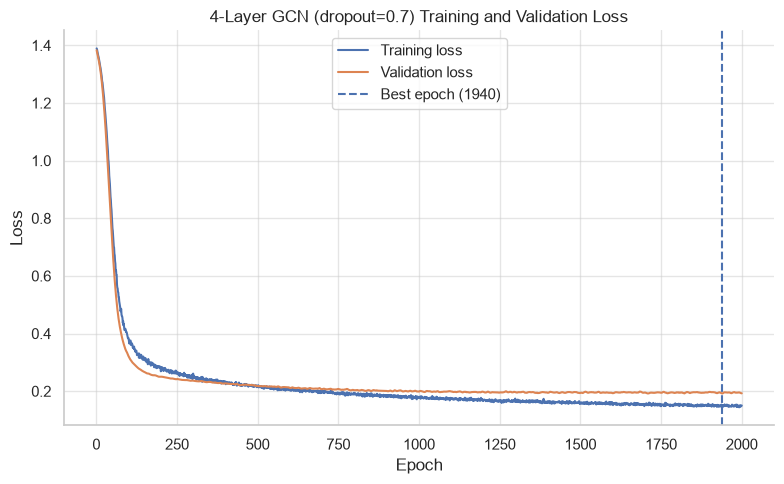

In [12]:
gcn4_loss_fig, _ = plot_training_validation_loss(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (dropout=0.7) Training and Validation Loss",
)

plt.show()

In [13]:
gcn4_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_dropout_070_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 4-Layer GCN (dropout=0.7)

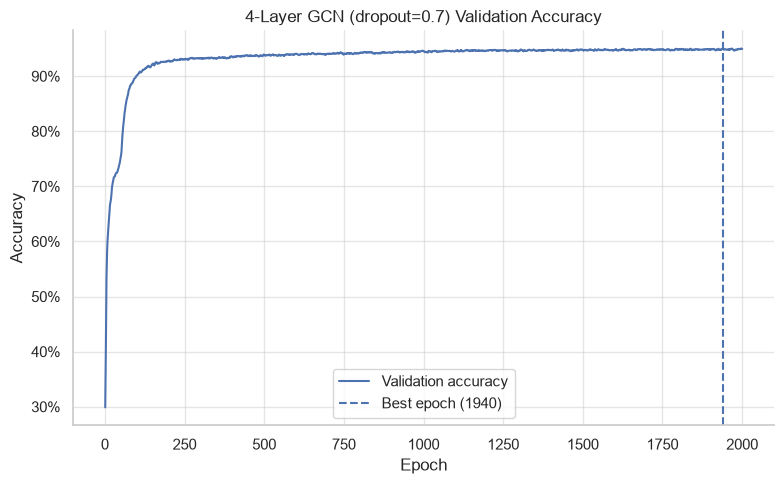

In [14]:
gcn4_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (dropout=0.7) Validation Accuracy",
)

plt.show()

In [15]:
gcn4_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_dropout_070_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 4-Layer GCN (dropout=0.7) Candidate Results

In [16]:
# save 4-Layer GCN (dropout=0.7) experiment results
gcn4_results = {
    "model": "GCN",
    "experiment": "dropout",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_07,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": gcn4_result["best_epoch"],
    "best_val_loss": gcn4_result["best_val_loss"],
    "training_seconds": gcn4_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn4_metrics,
    "history": gcn4_result["history"],
}

with (
    RESULTS_DIR / "gcn_dropout_070.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_result["best_state"],
    CHECKPOINTS_DIR / "gcn_dropout_070.pt",
)

The optimum for dropout=0.7 lands near the training boundary.<br>
Rerun with epochs=4000 to ensure a performance deterioration is observed beyond the current epochs=2000 best.

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 4-Layer GCN (dropout=0.7) network for 4000 epoch run

In [6]:
gcn4_model = GCNNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_07,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN (dropout=0.7) 4000 epoch run

In [7]:
# optimiser
gcn4_optimizer = torch.optim.Adam(
    gcn4_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

#### Evaluate 4-Layer GCN (dropout=0.7) Candidate over 4000 epochs

In [8]:
# perform training and validation of the 4-Layer GCN (dropout=0.7), 4000e

gcn4_result = train_gcn_model(
    model=gcn4_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn4_optimizer,
    epochs=EPOCHS_4K,
    print_every=100,
)

> Training GCN
Epoch [   1/4000] Train Loss: 1.38924 | Val Loss: 1.38280 | Val Acc: 29.88%
Epoch [ 100/4000] Train Loss: 0.38375 | Val Loss: 0.32093 | Val Acc: 90.12%
Epoch [ 200/4000] Train Loss: 0.26904 | Val Loss: 0.25021 | Val Acc: 92.81%
Epoch [ 300/4000] Train Loss: 0.26080 | Val Loss: 0.23641 | Val Acc: 93.21%
Epoch [ 400/4000] Train Loss: 0.23382 | Val Loss: 0.22693 | Val Acc: 93.52%
Epoch [ 500/4000] Train Loss: 0.21902 | Val Loss: 0.21769 | Val Acc: 93.88%
Epoch [ 600/4000] Train Loss: 0.20258 | Val Loss: 0.21128 | Val Acc: 94.06%
Epoch [ 700/4000] Train Loss: 0.19699 | Val Loss: 0.20708 | Val Acc: 94.15%
Epoch [ 800/4000] Train Loss: 0.19206 | Val Loss: 0.20315 | Val Acc: 94.19%
Epoch [ 900/4000] Train Loss: 0.17938 | Val Loss: 0.20065 | Val Acc: 94.24%
Epoch [1000/4000] Train Loss: 0.17630 | Val Loss: 0.19859 | Val Acc: 94.55%
Epoch [1100/4000] Train Loss: 0.17461 | Val Loss: 0.19877 | Val Acc: 94.55%
Epoch [1200/4000] Train Loss: 0.16744 | Val Loss: 0.19729 | Val Acc: 94.6

Restore best result for 4-Layer GCN (dropout=0.7) evaluation

In [9]:
# check that a best state exists
if gcn4_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn4_model.load_state_dict(
    gcn4_result["best_state"]
)

gcn4_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn4_logits = gcn4_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn4_metrics = classification_metrics(
    logits=gcn4_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 4-Layer GCN (dropout=0.7) evaluation metrics for the 4000e run


In [10]:
# print compact result summary
print(
    f"Best epoch:      {gcn4_result['best_epoch']}\n"
    f"Validation loss: {gcn4_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn4_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn4_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn4_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn4_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn4_metrics['macro_auroc']:.4f}"
)

Best epoch:      1940
Validation loss: 0.19184
Accuracy:        0.9495
Macro precision: 0.9491
Macro recall:    0.9457
Macro F1:        0.9473
Macro AUROC:     0.9916


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn4_metrics['precision'][i]:.4f}  "
        f"R={gcn4_metrics['recall'][i]:.4f}  "
        f"F1={gcn4_metrics['f1'][i]:.4f}  "
        f"n={gcn4_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9479  R=0.9530  F1=0.9505  n=1299
Government       P=0.9506  R=0.9513  F1=0.9510  n=1376
Company          P=0.9520  R=0.9627  F1=0.9573  n=1153
Politician       P=0.9457  R=0.9159  F1=0.9306  n=666


Visualise Validation Loss for the 4-Layer GCN (dropout=0.7) 4000 epoch run

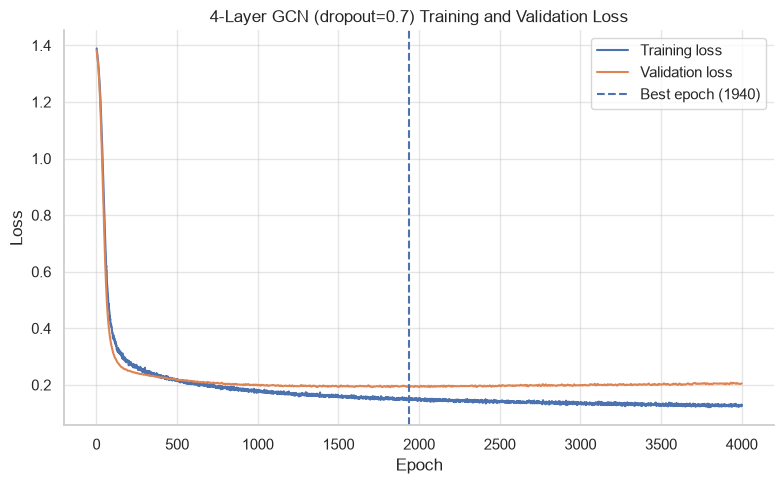

In [12]:
gcn4_loss_fig, _ = plot_training_validation_loss(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (dropout=0.7) Training and Validation Loss",
)

plt.show()

In [13]:
gcn4_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_dropout_070_training_validation_loss_4000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 4-Layer GCN (dropout=0.7)

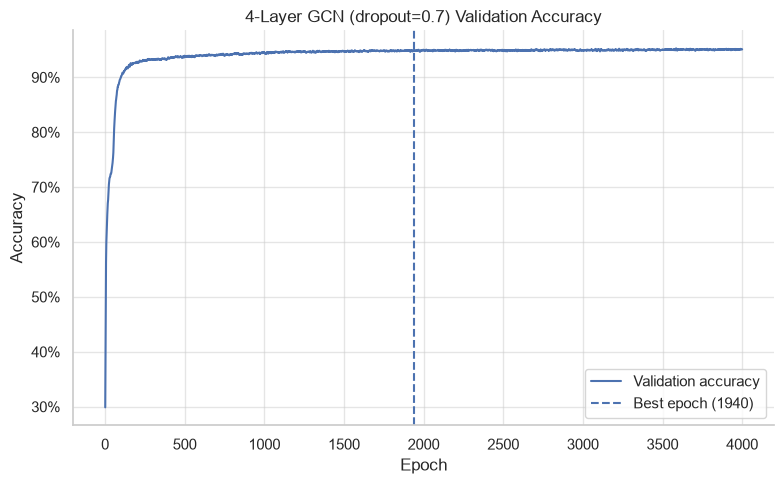

In [14]:
gcn4_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (dropout=0.7) Validation Accuracy",
)

plt.show()

In [15]:
gcn4_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_dropout_070_validation_accuracy_4000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 4-Layer GCN (dropout=0.7) Candidate Results from the 4000 epoch run

In [16]:
# save 4-Layer GCN (dropout=0.7) experiment results
gcn4_results = {
    "model": "GCN",
    "experiment": "dropout",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_4K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_07,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": gcn4_result["best_epoch"],
    "best_val_loss": gcn4_result["best_val_loss"],
    "training_seconds": gcn4_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn4_metrics,
    "history": gcn4_result["history"],
}

with (
    RESULTS_DIR / "gcn_dropout_070_4000e.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_result["best_state"],
    CHECKPOINTS_DIR / "gcn_dropout_070_4000e.pt",
)

Using a 4-layer GCN, the dropout=0.50 and dropout=0.55 form the 'best-performing region' for the metrics used.<br>
0.55 was selected as a compromise, because it preserves essentially the same class-balanced classification<br>
performance as 0.50, while moving modestly toward the lower validation loss observed at stronger dropout.

### Weight Decay Tuning

Reset the Torch seed rng

In [6]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 4-Layer GCN (weight_decay=1e-4) network

In [7]:
gcn4_model = GCNNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_055,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN (weight_decay=1e-4)

In [8]:
# optimiser
gcn4_wd1e4_optimizer = torch.optim.Adam(
    gcn4_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY_1E4,
)

#### Evaluate 4-Layer GCN (weight_decay=1e-4) Candidate

In [9]:
# perform training and validation of the 4-Layer GCN (weight_decay=1e-4)

gcn4_result = train_gcn_model(
    model=gcn4_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn4_wd1e4_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training GCN
Epoch [   1/2000] Train Loss: 1.38753 | Val Loss: 1.38259 | Val Acc: 29.86%
Epoch [ 100/2000] Train Loss: 0.34167 | Val Loss: 0.30679 | Val Acc: 90.54%
Epoch [ 200/2000] Train Loss: 0.24661 | Val Loss: 0.24556 | Val Acc: 92.92%
Epoch [ 300/2000] Train Loss: 0.22999 | Val Loss: 0.23316 | Val Acc: 93.24%
Epoch [ 400/2000] Train Loss: 0.20795 | Val Loss: 0.22229 | Val Acc: 93.75%
Epoch [ 500/2000] Train Loss: 0.19313 | Val Loss: 0.21378 | Val Acc: 93.75%
Epoch [ 600/2000] Train Loss: 0.18101 | Val Loss: 0.20684 | Val Acc: 94.19%
Epoch [ 700/2000] Train Loss: 0.17322 | Val Loss: 0.20463 | Val Acc: 94.13%
Epoch [ 800/2000] Train Loss: 0.16586 | Val Loss: 0.20087 | Val Acc: 94.33%
Epoch [ 900/2000] Train Loss: 0.15807 | Val Loss: 0.19668 | Val Acc: 94.53%
Epoch [1000/2000] Train Loss: 0.15440 | Val Loss: 0.19585 | Val Acc: 94.62%
Epoch [1100/2000] Train Loss: 0.14805 | Val Loss: 0.19375 | Val Acc: 94.75%
Epoch [1200/2000] Train Loss: 0.14529 | Val Loss: 0.19022 | Val Acc: 94.9

Restore best result for 4-Layer GCN (weight_decay=1e-4) evaluation

In [10]:
# check that a best state exists
if gcn4_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn4_model.load_state_dict(
    gcn4_result["best_state"]
)

gcn4_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn4_logits = gcn4_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn4_metrics = classification_metrics(
    logits=gcn4_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 4-Layer GCN (weight_decay=1e-4) evaluation metrics


In [11]:
# print compact result summary
print(
    f"Best epoch:      {gcn4_result['best_epoch']}\n"
    f"Validation loss: {gcn4_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn4_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn4_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn4_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn4_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn4_metrics['macro_auroc']:.4f}"
)

Best epoch:      1367
Validation loss: 0.18981
Accuracy:        0.9493
Macro precision: 0.9486
Macro recall:    0.9452
Macro F1:        0.9468
Macro AUROC:     0.9916


In [12]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn4_metrics['precision'][i]:.4f}  "
        f"R={gcn4_metrics['recall'][i]:.4f}  "
        f"F1={gcn4_metrics['f1'][i]:.4f}  "
        f"n={gcn4_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9480  R=0.9538  F1=0.9509  n=1299
Government       P=0.9513  R=0.9506  F1=0.9509  n=1376
Company          P=0.9512  R=0.9636  F1=0.9573  n=1153
Politician       P=0.9441  R=0.9129  F1=0.9282  n=666


Visualise Validation Loss for the 4-Layer GCN (weight_decay=1e-4)

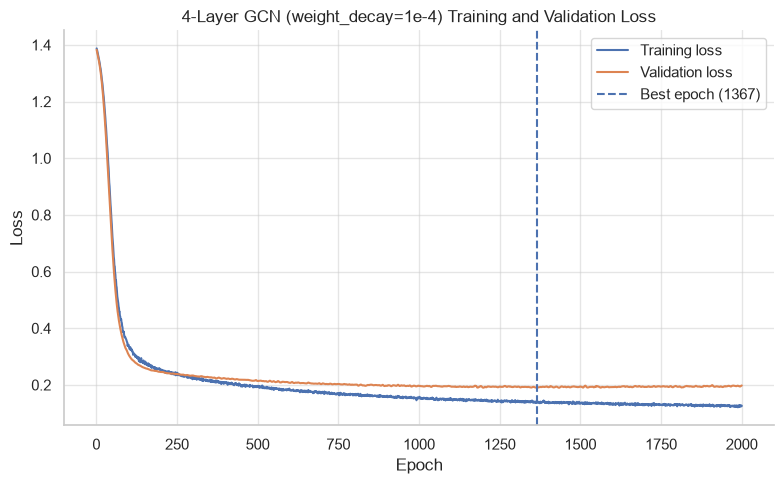

In [13]:
gcn4_loss_fig, _ = plot_training_validation_loss(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (weight_decay=1e-4) Training and Validation Loss",
)

plt.show()

In [14]:
gcn4_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_wd1e4_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 4-Layer GCN (weight_decay=1e-4)

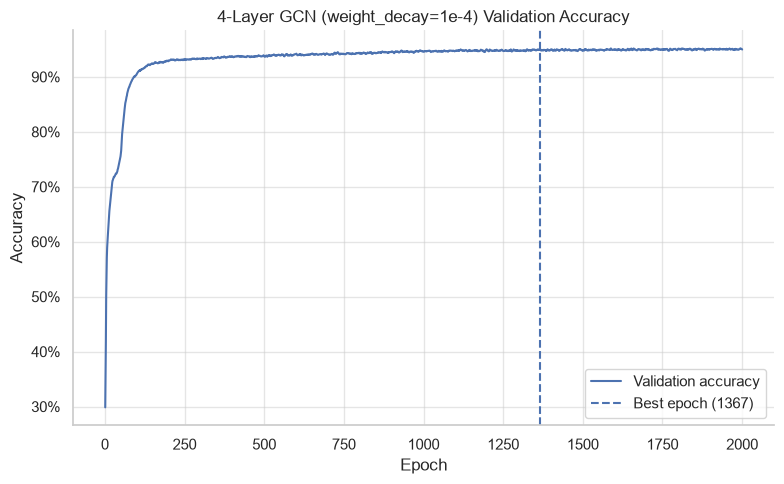

In [15]:
gcn4_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (weight_decay=1e-4) Validation Accuracy",
)

plt.show()

In [16]:
gcn4_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_wd1e4_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 4-Layer GCN (weight_decay=1e-4) Candidate Results

In [18]:
# save 4-Layer GCN (weight_decay=1e-4) experiment results
gcn4_results = {
    "model": "GCN",
    "experiment": "weight_decay",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_055,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY_1E4,
    "best_epoch": gcn4_result["best_epoch"],
    "best_val_loss": gcn4_result["best_val_loss"],
    "training_seconds": gcn4_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn4_metrics,
    "history": gcn4_result["history"],
}

with (
    RESULTS_DIR / "gcn_wd1e4.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_result["best_state"],
    CHECKPOINTS_DIR / "gcn_wd1e4.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 4-Layer GCN (weight_decay=5e-4) network

In [6]:
gcn4_model = GCNNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_055,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN (weight_decay=5e-4)

In [7]:
# optimiser
gcn4_wd5e4_optimizer = torch.optim.Adam(
    gcn4_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY_5E4,
)

#### Evaluate 4-Layer GCN (weight_decay=5e-4) Candidate

In [8]:
# perform training and validation of the 4-Layer GCN (weight_decay=5e-4)

gcn4_result = train_gcn_model(
    model=gcn4_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn4_wd5e4_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training GCN
Epoch [   1/2000] Train Loss: 1.38753 | Val Loss: 1.38269 | Val Acc: 29.75%
Epoch [ 100/2000] Train Loss: 0.34171 | Val Loss: 0.30788 | Val Acc: 90.50%
Epoch [ 200/2000] Train Loss: 0.24860 | Val Loss: 0.24712 | Val Acc: 92.68%
Epoch [ 300/2000] Train Loss: 0.23482 | Val Loss: 0.23546 | Val Acc: 93.26%
Epoch [ 400/2000] Train Loss: 0.21442 | Val Loss: 0.22498 | Val Acc: 93.52%
Epoch [ 500/2000] Train Loss: 0.20627 | Val Loss: 0.21841 | Val Acc: 93.70%
Epoch [ 600/2000] Train Loss: 0.19237 | Val Loss: 0.21304 | Val Acc: 93.95%
Epoch [ 700/2000] Train Loss: 0.18720 | Val Loss: 0.21117 | Val Acc: 94.08%
Epoch [ 800/2000] Train Loss: 0.18422 | Val Loss: 0.20762 | Val Acc: 94.13%
Epoch [ 900/2000] Train Loss: 0.17736 | Val Loss: 0.20342 | Val Acc: 94.21%
Epoch [1000/2000] Train Loss: 0.17173 | Val Loss: 0.20272 | Val Acc: 94.19%
Epoch [1100/2000] Train Loss: 0.17324 | Val Loss: 0.20054 | Val Acc: 94.37%
Epoch [1200/2000] Train Loss: 0.16700 | Val Loss: 0.19830 | Val Acc: 94.3

Restore best result for 4-Layer GCN (weight_decay=5e-4) evaluation

In [9]:
# check that a best state exists
if gcn4_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn4_model.load_state_dict(
    gcn4_result["best_state"]
)

gcn4_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn4_logits = gcn4_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn4_metrics = classification_metrics(
    logits=gcn4_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 4-Layer GCN (weight_decay=5e-4) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {gcn4_result['best_epoch']}\n"
    f"Validation loss: {gcn4_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn4_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn4_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn4_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn4_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn4_metrics['macro_auroc']:.4f}"
)

Best epoch:      1930
Validation loss: 0.19185
Accuracy:        0.9464
Macro precision: 0.9461
Macro recall:    0.9414
Macro F1:        0.9437
Macro AUROC:     0.9912


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn4_metrics['precision'][i]:.4f}  "
        f"R={gcn4_metrics['recall'][i]:.4f}  "
        f"F1={gcn4_metrics['f1'][i]:.4f}  "
        f"n={gcn4_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9486  R=0.9523  F1=0.9504  n=1299
Government       P=0.9431  R=0.9520  F1=0.9476  n=1376
Company          P=0.9493  R=0.9575  F1=0.9534  n=1153
Politician       P=0.9436  R=0.9039  F1=0.9233  n=666


Visualise Validation Loss for the 4-Layer GCN (weight_decay=5e-4)

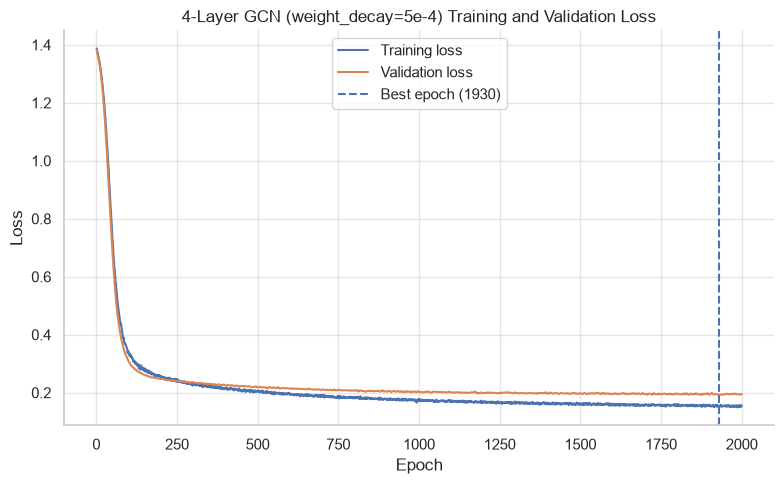

In [12]:
gcn4_loss_fig, _ = plot_training_validation_loss(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (weight_decay=5e-4) Training and Validation Loss",
)

plt.show()

In [13]:
gcn4_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_wd5e4_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 4-Layer GCN (weight_decay=5e-4)

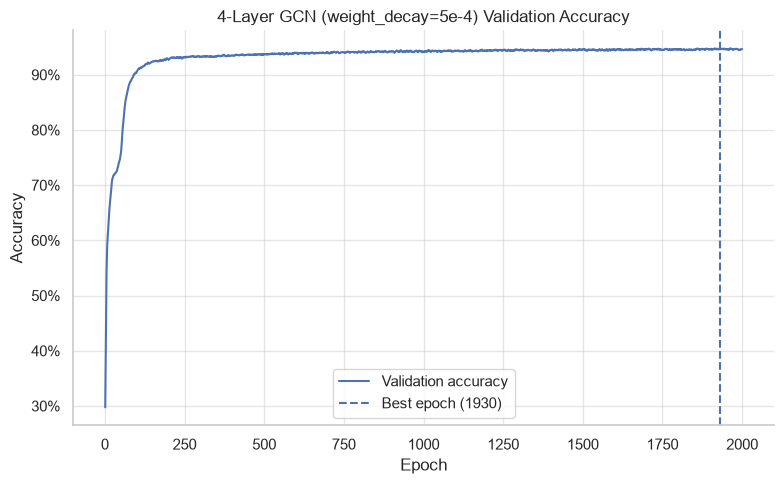

In [14]:
gcn4_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (weight_decay=5e-4) Validation Accuracy",
)

plt.show()

In [15]:
gcn4_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_wd5e4_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 4-Layer GCN (weight_decay=5e-4) Candidate Results

In [16]:
# save 4-Layer GCN (weight_decay=5e-4) experiment results
gcn4_results = {
    "model": "GCN",
    "experiment": "weight_decay",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_055,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY_5E4,
    "best_epoch": gcn4_result["best_epoch"],
    "best_val_loss": gcn4_result["best_val_loss"],
    "training_seconds": gcn4_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn4_metrics,
    "history": gcn4_result["history"],
}

with (
    RESULTS_DIR / "gcn_wd5e4.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_result["best_state"],
    CHECKPOINTS_DIR / "gcn_wd5e4.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 4-Layer GCN (weight_decay=1e-3) network

In [6]:
gcn4_model = GCNNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_055,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN (weight_decay=1e-3)

In [7]:
# optimiser
gcn4_wd1e3_optimizer = torch.optim.Adam(
    gcn4_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY_1E3,
)

#### Evaluate 4-Layer GCN (weight_decay=1e-3) Candidate

In [8]:
# perform training and validation of the 4-Layer GCN (weight_decay=1e-3)

gcn4_result = train_gcn_model(
    model=gcn4_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn4_wd1e3_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training GCN
Epoch [   1/2000] Train Loss: 1.38753 | Val Loss: 1.38288 | Val Acc: 29.44%
Epoch [ 100/2000] Train Loss: 0.34500 | Val Loss: 0.31113 | Val Acc: 90.50%
Epoch [ 200/2000] Train Loss: 0.25485 | Val Loss: 0.25096 | Val Acc: 92.63%
Epoch [ 300/2000] Train Loss: 0.24346 | Val Loss: 0.23977 | Val Acc: 93.15%
Epoch [ 400/2000] Train Loss: 0.22655 | Val Loss: 0.23008 | Val Acc: 93.35%
Epoch [ 500/2000] Train Loss: 0.22204 | Val Loss: 0.22489 | Val Acc: 93.39%
Epoch [ 600/2000] Train Loss: 0.21030 | Val Loss: 0.22130 | Val Acc: 93.66%
Epoch [ 700/2000] Train Loss: 0.20600 | Val Loss: 0.22052 | Val Acc: 93.88%
Epoch [ 800/2000] Train Loss: 0.20527 | Val Loss: 0.21742 | Val Acc: 93.86%
Epoch [ 900/2000] Train Loss: 0.19887 | Val Loss: 0.21413 | Val Acc: 93.99%
Epoch [1000/2000] Train Loss: 0.19354 | Val Loss: 0.21357 | Val Acc: 93.93%
Epoch [1100/2000] Train Loss: 0.19862 | Val Loss: 0.21212 | Val Acc: 93.99%
Epoch [1200/2000] Train Loss: 0.18923 | Val Loss: 0.20993 | Val Acc: 94.1

Restore best result for 4-Layer GCN (weight_decay=1e-3) evaluation

In [9]:
# check that a best state exists
if gcn4_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn4_model.load_state_dict(
    gcn4_result["best_state"]
)

gcn4_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn4_logits = gcn4_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn4_metrics = classification_metrics(
    logits=gcn4_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 4-Layer GCN (weight_decay=1e-3) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {gcn4_result['best_epoch']}\n"
    f"Validation loss: {gcn4_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn4_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn4_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn4_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn4_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn4_metrics['macro_auroc']:.4f}"
)

Best epoch:      1931
Validation loss: 0.20385
Accuracy:        0.9424
Macro precision: 0.9408
Macro recall:    0.9377
Macro F1:        0.9392
Macro AUROC:     0.9902


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn4_metrics['precision'][i]:.4f}  "
        f"R={gcn4_metrics['recall'][i]:.4f}  "
        f"F1={gcn4_metrics['f1'][i]:.4f}  "
        f"n={gcn4_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9462  R=0.9477  F1=0.9469  n=1299
Government       P=0.9441  R=0.9455  F1=0.9448  n=1376
Company          P=0.9427  R=0.9566  F1=0.9496  n=1153
Politician       P=0.9302  R=0.9009  F1=0.9153  n=666


Visualise Validation Loss for the 4-Layer GCN (weight_decay=1e-3)

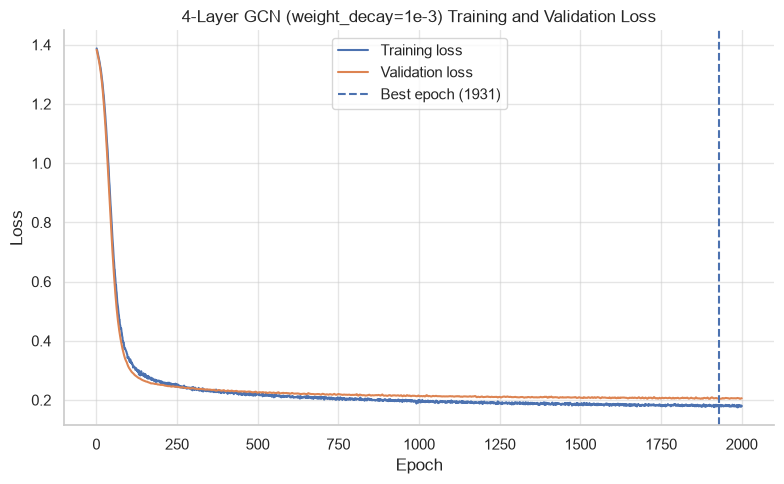

In [12]:
gcn4_loss_fig, _ = plot_training_validation_loss(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (weight_decay=1e-3) Training and Validation Loss",
)

plt.show()

In [13]:
gcn4_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_wd1e3_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 4-Layer GCN (weight_decay=1e-3)

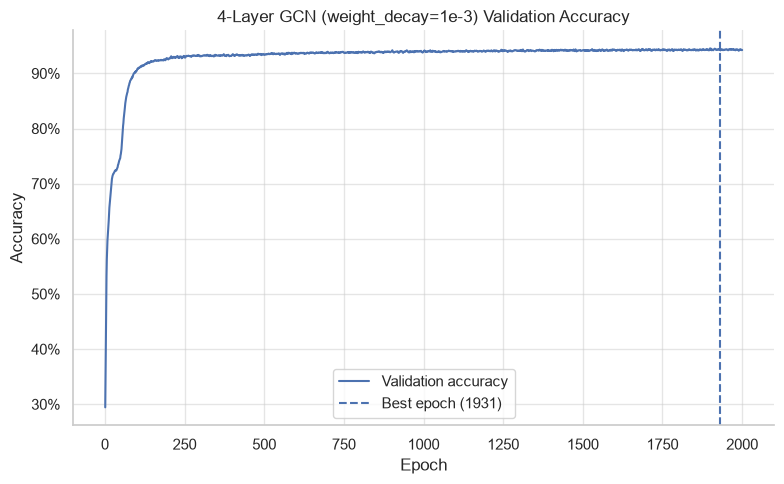

In [14]:
gcn4_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (weight_decay=1e-3) Validation Accuracy",
)

plt.show()

In [15]:
gcn4_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_wd1e3_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 4-Layer GCN (weight_decay=1e-3) Candidate Results

In [16]:
# save 4-Layer GCN (weight_decay=1e-3) experiment results
gcn4_results = {
    "model": "GCN",
    "experiment": "weight_decay",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_055,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY_1E3,
    "best_epoch": gcn4_result["best_epoch"],
    "best_val_loss": gcn4_result["best_val_loss"],
    "training_seconds": gcn4_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn4_metrics,
    "history": gcn4_result["history"],
}

with (
    RESULTS_DIR / "gcn_wd1e3.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_result["best_state"],
    CHECKPOINTS_DIR / "gcn_wd1e3.pt",
)

The best weight decay metrics are shared between 0 and 1e-4<br>
Weight decay of 5e-4 and 1e-3 have optimal values that would typically warrant 4000-epoch runs,<br>
however, all metrics are worse than for weight decay values of 0 and 1e-4, so longer runs will<br>
not be performed.<br>
Instead, a run using weight decay of 5e-5 will be performed to investigate whether it provides a<br>
useful compromise between the 0 and 1e-4 weight decay values.

Reset the Torch seed rng

In [6]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 4-Layer GCN (weight_decay=5e-5) network

In [7]:
gcn4_model = GCNNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_055,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN (weight_decay=5e-5)

In [8]:
# optimiser
gcn4_wd5e5_optimizer = torch.optim.Adam(
    gcn4_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY_5E5,
)

#### Evaluate 4-Layer GCN (weight_decay=5e-5) Candidate

In [9]:
# perform training and validation of the 4-Layer GCN (weight_decay=5e-5)

gcn4_result = train_gcn_model(
    model=gcn4_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn4_wd5e5_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training GCN
Epoch [   1/2000] Train Loss: 1.38753 | Val Loss: 1.38258 | Val Acc: 29.86%
Epoch [ 100/2000] Train Loss: 0.34180 | Val Loss: 0.30676 | Val Acc: 90.54%
Epoch [ 200/2000] Train Loss: 0.24654 | Val Loss: 0.24556 | Val Acc: 92.86%
Epoch [ 300/2000] Train Loss: 0.22941 | Val Loss: 0.23299 | Val Acc: 93.26%
Epoch [ 400/2000] Train Loss: 0.20722 | Val Loss: 0.22234 | Val Acc: 93.75%
Epoch [ 500/2000] Train Loss: 0.19235 | Val Loss: 0.21380 | Val Acc: 93.84%
Epoch [ 600/2000] Train Loss: 0.18037 | Val Loss: 0.20700 | Val Acc: 94.17%
Epoch [ 700/2000] Train Loss: 0.17273 | Val Loss: 0.20460 | Val Acc: 94.17%
Epoch [ 800/2000] Train Loss: 0.16399 | Val Loss: 0.20069 | Val Acc: 94.39%
Epoch [ 900/2000] Train Loss: 0.15613 | Val Loss: 0.19715 | Val Acc: 94.66%
Epoch [1000/2000] Train Loss: 0.15251 | Val Loss: 0.19691 | Val Acc: 94.68%
Epoch [1100/2000] Train Loss: 0.14575 | Val Loss: 0.19477 | Val Acc: 94.79%
Epoch [1200/2000] Train Loss: 0.14235 | Val Loss: 0.19183 | Val Acc: 94.9

Restore best result for 4-Layer GCN (weight_decay=5e-5) evaluation

In [10]:
# check that a best state exists
if gcn4_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn4_model.load_state_dict(
    gcn4_result["best_state"]
)

gcn4_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn4_logits = gcn4_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn4_metrics = classification_metrics(
    logits=gcn4_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 4-Layer GCN (weight_decay=5e-5) evaluation metrics


In [11]:
# print compact result summary
print(
    f"Best epoch:      {gcn4_result['best_epoch']}\n"
    f"Validation loss: {gcn4_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn4_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn4_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn4_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn4_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn4_metrics['macro_auroc']:.4f}"
)

Best epoch:      1367
Validation loss: 0.19127
Accuracy:        0.9506
Macro precision: 0.9495
Macro recall:    0.9476
Macro F1:        0.9485
Macro AUROC:     0.9916


In [12]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn4_metrics['precision'][i]:.4f}  "
        f"R={gcn4_metrics['recall'][i]:.4f}  "
        f"F1={gcn4_metrics['f1'][i]:.4f}  "
        f"n={gcn4_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9545  R=0.9523  F1=0.9534  n=1299
Government       P=0.9479  R=0.9528  F1=0.9503  n=1376
Company          P=0.9552  R=0.9618  F1=0.9585  n=1153
Politician       P=0.9404  R=0.9234  F1=0.9318  n=666


Visualise Validation Loss for the 4-Layer GCN (weight_decay=5e-5)

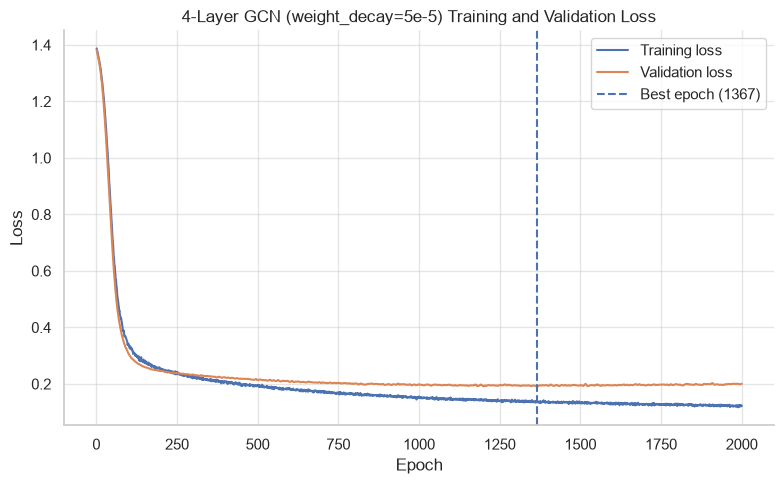

In [13]:
gcn4_loss_fig, _ = plot_training_validation_loss(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (weight_decay=5e-5) Training and Validation Loss",
)

plt.show()

In [14]:
gcn4_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_wd5e5_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 4-Layer GCN (weight_decay=5e-5)

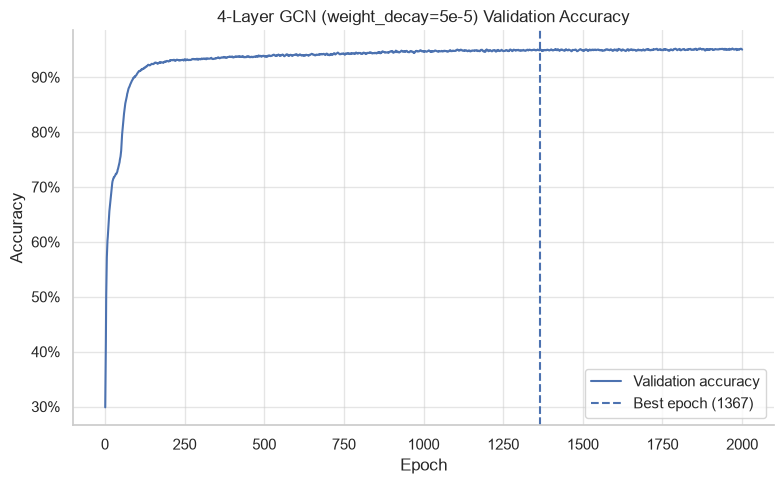

In [15]:
gcn4_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (weight_decay=5e-5) Validation Accuracy",
)

plt.show()

In [16]:
gcn4_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_wd5e5_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 4-Layer GCN (weight_decay=5e-5) Candidate Results

In [17]:
# save 4-Layer GCN (weight_decay=5e-5) experiment results
gcn4_results = {
    "model": "GCN",
    "experiment": "weight_decay",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_055,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY_5E5,
    "best_epoch": gcn4_result["best_epoch"],
    "best_val_loss": gcn4_result["best_val_loss"],
    "training_seconds": gcn4_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn4_metrics,
    "history": gcn4_result["history"],
}

with (
    RESULTS_DIR / "gcn_wd5e5.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_result["best_state"],
    CHECKPOINTS_DIR / "gcn_wd5e5.pt",
)

The use of weight_decay=5e-5 yields the 'best-performing region' across essentially the whole validation picture.

### Hidden Layers

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 4-Layer GCN (hidden_channels=32) network

In [6]:
gcn4_hc32_model = GCNNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS_32,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_055,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN (hidden_channels=32)

In [7]:
# optimiser
gcn4_hc32_optimizer = torch.optim.Adam(
    gcn4_hc32_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY_5E5,
)

#### Evaluate 4-Layer GCN (hidden_channels=32) Candidate

In [8]:
# perform training and validation of the 4-Layer GCN (hidden_channels=32)

gcn4_result = train_gcn_model(
    model=gcn4_hc32_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn4_hc32_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training GCN
Epoch [   1/2000] Train Loss: 1.38013 | Val Loss: 1.37703 | Val Acc: 30.73%
Epoch [ 100/2000] Train Loss: 0.56352 | Val Loss: 0.49470 | Val Acc: 84.76%
Epoch [ 200/2000] Train Loss: 0.30242 | Val Loss: 0.27492 | Val Acc: 91.46%
Epoch [ 300/2000] Train Loss: 0.26916 | Val Loss: 0.25136 | Val Acc: 92.59%
Epoch [ 400/2000] Train Loss: 0.24829 | Val Loss: 0.23982 | Val Acc: 93.15%
Epoch [ 500/2000] Train Loss: 0.23638 | Val Loss: 0.23336 | Val Acc: 93.32%
Epoch [ 600/2000] Train Loss: 0.22815 | Val Loss: 0.22726 | Val Acc: 93.66%
Epoch [ 700/2000] Train Loss: 0.21461 | Val Loss: 0.22297 | Val Acc: 93.77%
Epoch [ 800/2000] Train Loss: 0.21103 | Val Loss: 0.21874 | Val Acc: 93.95%
Epoch [ 900/2000] Train Loss: 0.20920 | Val Loss: 0.21458 | Val Acc: 93.97%
Epoch [1000/2000] Train Loss: 0.20250 | Val Loss: 0.21121 | Val Acc: 94.06%
Epoch [1100/2000] Train Loss: 0.19347 | Val Loss: 0.20895 | Val Acc: 94.06%
Epoch [1200/2000] Train Loss: 0.19074 | Val Loss: 0.20767 | Val Acc: 94.0

Restore best result for 4-Layer GCN (hidden_channels=32) evaluation

In [9]:
# check that a best state exists
if gcn4_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn4_hc32_model.load_state_dict(
    gcn4_result["best_state"]
)

gcn4_hc32_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn4_logits = gcn4_hc32_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn4_metrics = classification_metrics(
    logits=gcn4_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 4-Layer GCN (hidden_channels=32) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {gcn4_result['best_epoch']}\n"
    f"Validation loss: {gcn4_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn4_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn4_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn4_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn4_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn4_metrics['macro_auroc']:.4f}"
)

Best epoch:      1970
Validation loss: 0.19780
Accuracy:        0.9448
Macro precision: 0.9425
Macro recall:    0.9408
Macro F1:        0.9416
Macro AUROC:     0.9910


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn4_metrics['precision'][i]:.4f}  "
        f"R={gcn4_metrics['recall'][i]:.4f}  "
        f"F1={gcn4_metrics['f1'][i]:.4f}  "
        f"n={gcn4_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9481  R=0.9423  F1=0.9452  n=1299
Government       P=0.9471  R=0.9506  F1=0.9489  n=1376
Company          P=0.9495  R=0.9618  F1=0.9556  n=1153
Politician       P=0.9251  R=0.9084  F1=0.9167  n=666


Visualise Validation Loss for the 4-Layer GCN (hidden_channels=32)

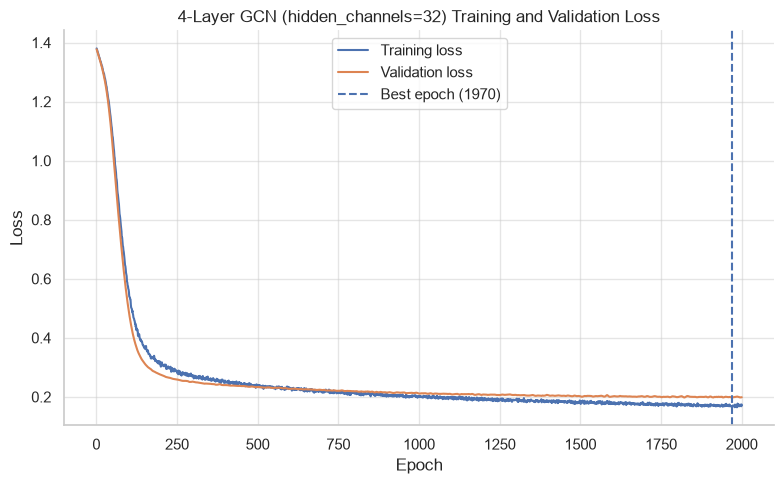

In [12]:
gcn4_loss_fig, _ = plot_training_validation_loss(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (hidden_channels=32) Training and Validation Loss",
)

plt.show()

In [13]:
gcn4_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_hc32_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 4-Layer GCN (hidden_channels=32)

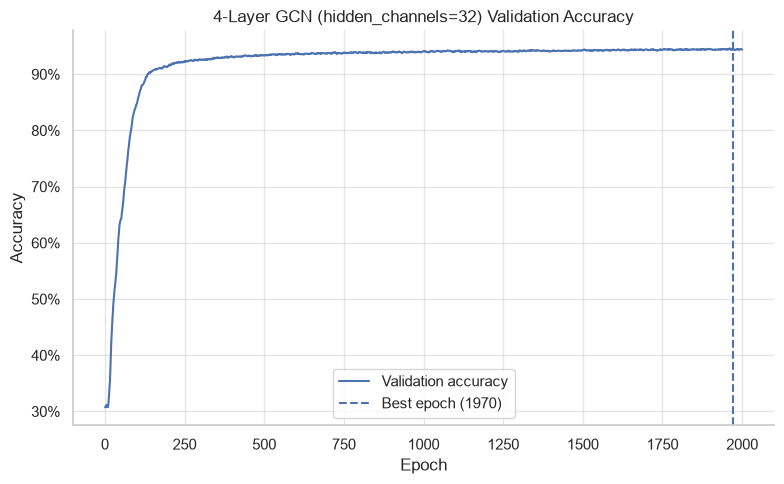

In [14]:
gcn4_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (hidden_channels=32) Validation Accuracy",
)

plt.show()

In [15]:
gcn4_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_hc32_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 4-Layer GCN (hidden_channels=32) Candidate Results

In [16]:
# save 4-Layer GCN (hidden_channels=32) experiment results
gcn4_results = {
    "model": "GCN",
    "experiment": "hidden_channels",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS_32,
    "dropout": DROPOUT_055,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY_5E5,
    "best_epoch": gcn4_result["best_epoch"],
    "best_val_loss": gcn4_result["best_val_loss"],
    "training_seconds": gcn4_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn4_metrics,
    "history": gcn4_result["history"],
}

with (
    RESULTS_DIR / "gcn_hc32.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_result["best_state"],
    CHECKPOINTS_DIR / "gcn_hc32.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 4-Layer GCN (hidden_channels=128) network

In [6]:
gcn4_hc128_model = GCNNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS_128,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_055,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN (hidden_channels=128)

In [7]:
# optimiser
gcn4_hc128_optimizer = torch.optim.Adam(
    gcn4_hc128_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY_5E5,
)

#### Evaluate 4-Layer GCN (hidden_channels=128) Candidate

In [8]:
# perform training and validation of the 4-Layer GCN (hidden_channels=128)

gcn4_result = train_gcn_model(
    model=gcn4_hc128_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn4_hc128_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training GCN
Epoch [   1/2000] Train Loss: 1.39435 | Val Loss: 1.37685 | Val Acc: 30.46%
Epoch [ 100/2000] Train Loss: 0.25968 | Val Loss: 0.25387 | Val Acc: 92.57%
Epoch [ 200/2000] Train Loss: 0.20208 | Val Loss: 0.22578 | Val Acc: 93.46%
Epoch [ 300/2000] Train Loss: 0.17285 | Val Loss: 0.20812 | Val Acc: 94.24%
Epoch [ 400/2000] Train Loss: 0.15866 | Val Loss: 0.19925 | Val Acc: 94.48%
Epoch [ 500/2000] Train Loss: 0.14555 | Val Loss: 0.19542 | Val Acc: 94.77%
Epoch [ 600/2000] Train Loss: 0.13761 | Val Loss: 0.19186 | Val Acc: 94.88%
Epoch [ 700/2000] Train Loss: 0.12906 | Val Loss: 0.19238 | Val Acc: 94.99%
Epoch [ 800/2000] Train Loss: 0.12226 | Val Loss: 0.19408 | Val Acc: 95.10%
Epoch [ 900/2000] Train Loss: 0.11747 | Val Loss: 0.19564 | Val Acc: 94.86%
Epoch [1000/2000] Train Loss: 0.11081 | Val Loss: 0.19631 | Val Acc: 95.06%
Epoch [1100/2000] Train Loss: 0.10748 | Val Loss: 0.20017 | Val Acc: 95.13%
Epoch [1200/2000] Train Loss: 0.10454 | Val Loss: 0.20144 | Val Acc: 95.0

Restore best result for 4-Layer GCN (hidden_channels=128) evaluation

In [9]:
# check that a best state exists
if gcn4_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn4_hc128_model.load_state_dict(
    gcn4_result["best_state"]
)

gcn4_hc128_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn4_logits = gcn4_hc128_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn4_metrics = classification_metrics(
    logits=gcn4_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 4-Layer GCN (hidden_channels=128) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {gcn4_result['best_epoch']}\n"
    f"Validation loss: {gcn4_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn4_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn4_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn4_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn4_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn4_metrics['macro_auroc']:.4f}"
)

Best epoch:      643
Validation loss: 0.18875
Accuracy:        0.9499
Macro precision: 0.9490
Macro recall:    0.9469
Macro F1:        0.9479
Macro AUROC:     0.9919


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn4_metrics['precision'][i]:.4f}  "
        f"R={gcn4_metrics['recall'][i]:.4f}  "
        f"F1={gcn4_metrics['f1'][i]:.4f}  "
        f"n={gcn4_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9529  R=0.9500  F1=0.9514  n=1299
Government       P=0.9479  R=0.9520  F1=0.9500  n=1376
Company          P=0.9536  R=0.9636  F1=0.9586  n=1153
Politician       P=0.9417  R=0.9219  F1=0.9317  n=666


Visualise Validation Loss for the 4-Layer GCN (hidden_channels=128)

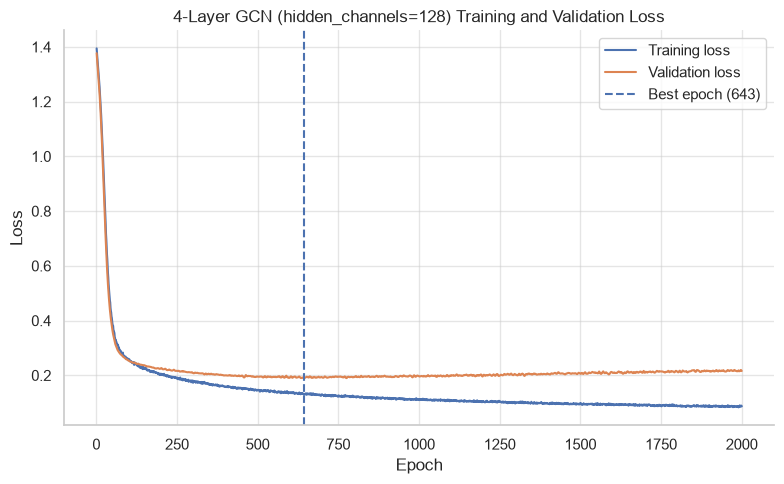

In [12]:
gcn4_loss_fig, _ = plot_training_validation_loss(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (hidden_channels=128) Training and Validation Loss",
)

plt.show()

In [13]:
gcn4_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_hc128_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 4-Layer GCN (hidden_channels=128)

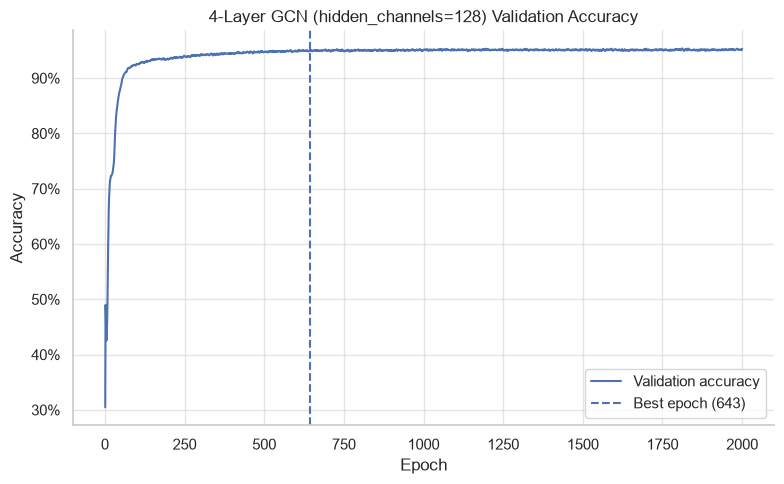

In [14]:
gcn4_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (hidden_channels=128) Validation Accuracy",
)

plt.show()

In [15]:
gcn4_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_hc128_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 4-Layer GCN (hidden_channels=128) Candidate Results

In [16]:
# save 4-Layer GCN (hidden_channels=128) experiment results
gcn4_results = {
    "model": "GCN",
    "experiment": "hidden_channels",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS_128,
    "dropout": DROPOUT_055,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY_5E5,
    "best_epoch": gcn4_result["best_epoch"],
    "best_val_loss": gcn4_result["best_val_loss"],
    "training_seconds": gcn4_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn4_metrics,
    "history": gcn4_result["history"],
}

with (
    RESULTS_DIR / "gcn_hc128.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_result["best_state"],
    CHECKPOINTS_DIR / "gcn_hc128.pt",
)

Reducing hidden width from 64 to 32 substantially slowed convergence and reduced validation performance.<br>
Best validation loss occurred near the 2000-epoch boundary, but classification metrics plateaued below<br>
those of the 64-channel model, so a 4000e run is unlikely to be of value.<br>
128 channels reduced validation cross-entropy and slightly increased AUROC, but without meaningful<br>
improvement in accuracy, macro-F1, or per-class performance, while training cost increased substantially.<br>
Therefore, proceeding with 64 hidden channels.

### Learning Rate

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 4-Layer GCN (learning_rate=5e-4) network

In [6]:
gcn4_model = GCNNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_055,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN (learning_rate=5e-4)

In [7]:
# optimiser
gcn4_lr5e4_optimizer = torch.optim.Adam(
    gcn4_model.parameters(),
    lr=LEARNING_RATE_5E4,
    weight_decay=WEIGHT_DECAY_5E5,
)

#### Evaluate 4-Layer GCN (learning_rate=5e-4) Candidate

In [8]:
# perform training and validation of the 4-Layer GCN (learning_rate=5e-4)

gcn4_result = train_gcn_model(
    model=gcn4_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn4_lr5e4_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training GCN
Epoch [   1/2000] Train Loss: 1.38753 | Val Loss: 1.38532 | Val Acc: 26.23%
Epoch [ 100/2000] Train Loss: 0.60614 | Val Loss: 0.56009 | Val Acc: 82.04%
Epoch [ 200/2000] Train Loss: 0.31062 | Val Loss: 0.28824 | Val Acc: 91.28%
Epoch [ 300/2000] Train Loss: 0.27639 | Val Loss: 0.25543 | Val Acc: 92.59%
Epoch [ 400/2000] Train Loss: 0.24632 | Val Loss: 0.24201 | Val Acc: 93.06%
Epoch [ 500/2000] Train Loss: 0.23344 | Val Loss: 0.23498 | Val Acc: 93.19%
Epoch [ 600/2000] Train Loss: 0.21883 | Val Loss: 0.22827 | Val Acc: 93.48%
Epoch [ 700/2000] Train Loss: 0.21026 | Val Loss: 0.22397 | Val Acc: 93.59%
Epoch [ 800/2000] Train Loss: 0.20179 | Val Loss: 0.21906 | Val Acc: 93.68%
Epoch [ 900/2000] Train Loss: 0.19259 | Val Loss: 0.21504 | Val Acc: 93.88%
Epoch [1000/2000] Train Loss: 0.18668 | Val Loss: 0.21352 | Val Acc: 93.97%
Epoch [1100/2000] Train Loss: 0.18235 | Val Loss: 0.21025 | Val Acc: 94.04%
Epoch [1200/2000] Train Loss: 0.17581 | Val Loss: 0.20792 | Val Acc: 94.0

Restore best result for 4-Layer GCN (learning_rate=5e-4) evaluation

In [9]:
# check that a best state exists
if gcn4_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn4_model.load_state_dict(
    gcn4_result["best_state"]
)

gcn4_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn4_logits = gcn4_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn4_metrics = classification_metrics(
    logits=gcn4_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 4-Layer GCN (learning_rate=5e-4) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {gcn4_result['best_epoch']}\n"
    f"Validation loss: {gcn4_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn4_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn4_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn4_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn4_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn4_metrics['macro_auroc']:.4f}"
)

Best epoch:      1942
Validation loss: 0.19424
Accuracy:        0.9486
Macro precision: 0.9478
Macro recall:    0.9447
Macro F1:        0.9462
Macro AUROC:     0.9912


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn4_metrics['precision'][i]:.4f}  "
        f"R={gcn4_metrics['recall'][i]:.4f}  "
        f"F1={gcn4_metrics['f1'][i]:.4f}  "
        f"n={gcn4_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9480  R=0.9546  F1=0.9513  n=1299
Government       P=0.9519  R=0.9484  F1=0.9501  n=1376
Company          P=0.9487  R=0.9627  F1=0.9557  n=1153
Politician       P=0.9426  R=0.9129  F1=0.9275  n=666


Visualise Validation Loss for the 4-Layer GCN (learning_rate=5e-4)

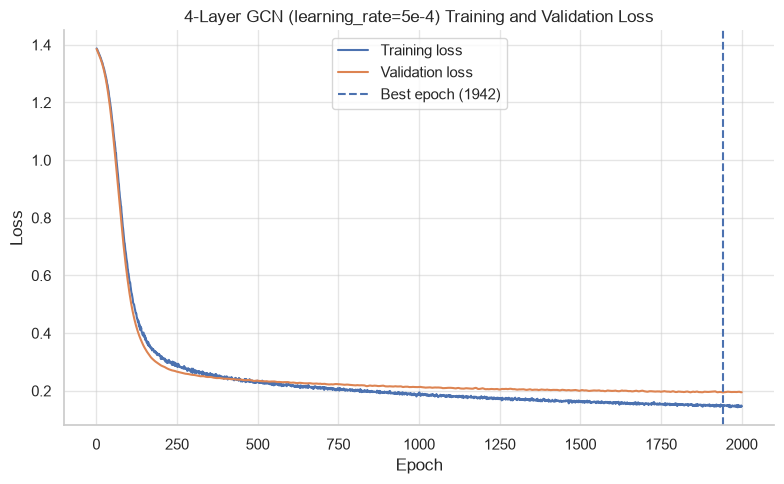

In [12]:
gcn4_loss_fig, _ = plot_training_validation_loss(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (learning_rate=5e-4) Training and Validation Loss",
)

plt.show()

In [13]:
gcn4_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_lr5e4_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 4-Layer GCN (learning_rate=5e-4)

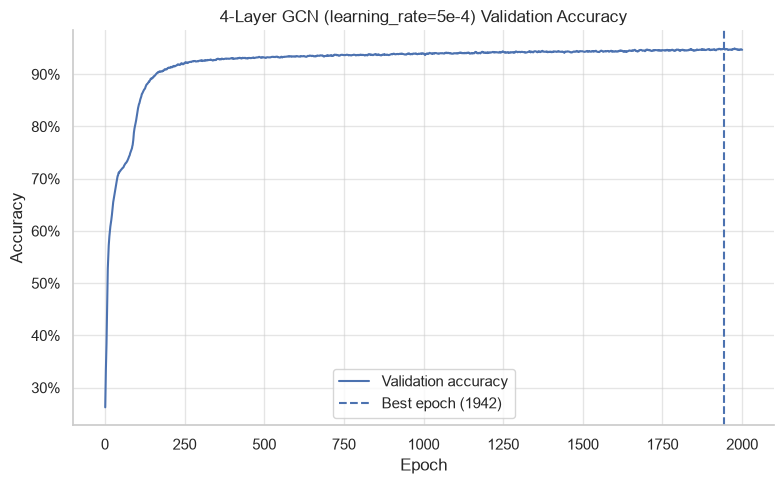

In [14]:
gcn4_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (learning_rate=5e-4) Validation Accuracy",
)

plt.show()

In [15]:
gcn4_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_lr5e4_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 4-Layer GCN (learning_rate=5e-4) Candidate Results

In [16]:
# save 4-Layer GCN (learning_rate=5e-4) experiment results
gcn4_results = {
    "model": "GCN",
    "experiment": "learning_rate",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_055,
    "learning_rate": LEARNING_RATE_5E4,
    "weight_decay": WEIGHT_DECAY_5E5,
    "best_epoch": gcn4_result["best_epoch"],
    "best_val_loss": gcn4_result["best_val_loss"],
    "training_seconds": gcn4_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn4_metrics,
    "history": gcn4_result["history"],
}

with (
    RESULTS_DIR / "gcn_lr5e4.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_result["best_state"],
    CHECKPOINTS_DIR / "gcn_lr5e4.pt",
)

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 4-Layer GCN (learning_rate=2e-3) network

In [6]:
gcn4_model = GCNNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_055,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN (learning_rate=2e-3)

In [7]:
# optimiser
gcn4_lr2e3_optimizer = torch.optim.Adam(
    gcn4_model.parameters(),
    lr=LEARNING_RATE_2E3,
    weight_decay=WEIGHT_DECAY_5E5,
)

#### Evaluate 4-Layer GCN (learning_rate=2e-3) Candidate

In [8]:
# perform training and validation of the 4-Layer GCN (learning_rate=2e-3)

gcn4_result = train_gcn_model(
    model=gcn4_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn4_lr2e3_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training GCN
Epoch [   1/2000] Train Loss: 1.38753 | Val Loss: 1.37729 | Val Acc: 35.36%
Epoch [ 100/2000] Train Loss: 0.26774 | Val Loss: 0.25161 | Val Acc: 92.81%
Epoch [ 200/2000] Train Loss: 0.21081 | Val Loss: 0.22641 | Val Acc: 93.46%
Epoch [ 300/2000] Train Loss: 0.19222 | Val Loss: 0.21278 | Val Acc: 94.04%
Epoch [ 400/2000] Train Loss: 0.17009 | Val Loss: 0.20351 | Val Acc: 94.33%
Epoch [ 500/2000] Train Loss: 0.15825 | Val Loss: 0.19989 | Val Acc: 94.44%
Epoch [ 600/2000] Train Loss: 0.14614 | Val Loss: 0.19515 | Val Acc: 94.73%
Epoch [ 700/2000] Train Loss: 0.14037 | Val Loss: 0.19615 | Val Acc: 94.82%
Epoch [ 800/2000] Train Loss: 0.13502 | Val Loss: 0.19638 | Val Acc: 94.95%
Epoch [ 900/2000] Train Loss: 0.12967 | Val Loss: 0.19469 | Val Acc: 95.15%
Epoch [1000/2000] Train Loss: 0.12579 | Val Loss: 0.19633 | Val Acc: 95.04%
Epoch [1100/2000] Train Loss: 0.12345 | Val Loss: 0.19934 | Val Acc: 95.08%
Epoch [1200/2000] Train Loss: 0.12014 | Val Loss: 0.19645 | Val Acc: 95.0

Restore best result for 4-Layer GCN (learning_rate=2e-3) evaluation

In [9]:
# check that a best state exists
if gcn4_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn4_model.load_state_dict(
    gcn4_result["best_state"]
)

gcn4_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn4_logits = gcn4_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn4_metrics = classification_metrics(
    logits=gcn4_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 4-Layer GCN (learning_rate=2e-3) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {gcn4_result['best_epoch']}\n"
    f"Validation loss: {gcn4_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn4_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn4_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn4_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn4_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn4_metrics['macro_auroc']:.4f}"
)

Best epoch:      834
Validation loss: 0.19177
Accuracy:        0.9495
Macro precision: 0.9484
Macro recall:    0.9466
Macro F1:        0.9475
Macro AUROC:     0.9916


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn4_metrics['precision'][i]:.4f}  "
        f"R={gcn4_metrics['recall'][i]:.4f}  "
        f"F1={gcn4_metrics['f1'][i]:.4f}  "
        f"n={gcn4_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9501  R=0.9523  F1=0.9512  n=1299
Government       P=0.9506  R=0.9506  F1=0.9506  n=1376
Company          P=0.9527  R=0.9601  F1=0.9564  n=1153
Politician       P=0.9404  R=0.9234  F1=0.9318  n=666


Visualise Validation Loss for the 4-Layer GCN (learning_rate=2e-3)

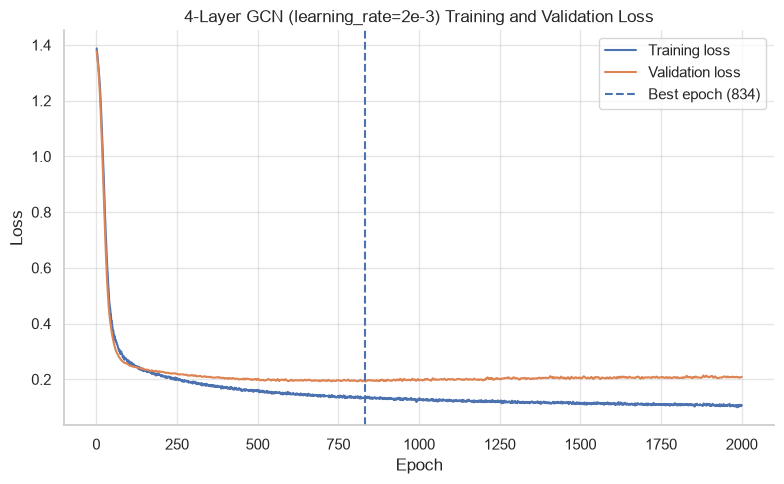

In [12]:
gcn4_loss_fig, _ = plot_training_validation_loss(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (learning_rate=2e-3) Training and Validation Loss",
)

plt.show()

In [13]:
gcn4_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_lr2e3_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 4-Layer GCN (learning_rate=2e-3)

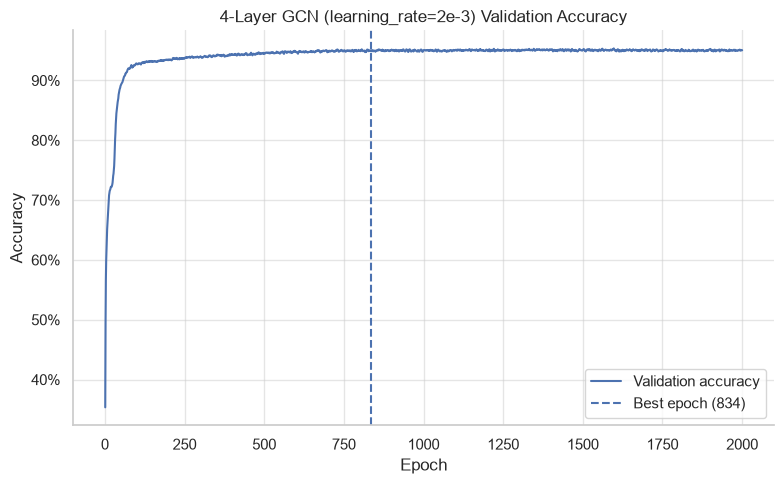

In [14]:
gcn4_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (learning_rate=2e-3) Validation Accuracy",
)

plt.show()

In [15]:
gcn4_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_lr2e3_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 4-Layer GCN (learning_rate=2e-3) Candidate Results

In [16]:
# save 4-Layer GCN (learning_rate=2e-3) experiment results
gcn4_results = {
    "model": "GCN",
    "experiment": "learning_rate",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_055,
    "learning_rate": LEARNING_RATE_2E3,
    "weight_decay": WEIGHT_DECAY_5E5,
    "best_epoch": gcn4_result["best_epoch"],
    "best_val_loss": gcn4_result["best_val_loss"],
    "training_seconds": gcn4_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn4_metrics,
    "history": gcn4_result["history"],
}

with (
    RESULTS_DIR / "gcn_lr2e3.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_result["best_state"],
    CHECKPOINTS_DIR / "gcn_lr2e3.pt",
)

The reduced learning rate of 5e-4 delayed convergence while producing weaker validation metrics.<br>
The increased learning rate of 2e-3 accelerated convergence but did not improve validation performance.<br>
The existing learning rateof 1e-3 provides the best balance of convergence rate and predictive performance.<br>
The 1e-3 learning rate will be retained.

### Activation Function

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 4-Layer GCN (activation: ELU) network

In [6]:
gcn4_elu_model = GCNNetwork4LayerELU(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_055,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN (activation: ELU)

In [7]:
# optimiser
gcn4_elu_optimizer = torch.optim.Adam(
    gcn4_elu_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY_5E5,
)

#### Evaluate 4-Layer GCN (activation: ELU) Candidate

In [8]:
# perform training and validation of the 4-Layer GCN (activation: ELU)

gcn4_result = train_gcn_model(
    model=gcn4_elu_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn4_elu_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training GCN
Epoch [   1/2000] Train Loss: 1.39069 | Val Loss: 1.36451 | Val Acc: 33.82%
Epoch [ 100/2000] Train Loss: 0.31610 | Val Loss: 0.30087 | Val Acc: 90.88%
Epoch [ 200/2000] Train Loss: 0.25530 | Val Loss: 0.26468 | Val Acc: 92.15%
Epoch [ 300/2000] Train Loss: 0.24548 | Val Loss: 0.25699 | Val Acc: 92.81%
Epoch [ 400/2000] Train Loss: 0.23559 | Val Loss: 0.25278 | Val Acc: 93.08%
Epoch [ 500/2000] Train Loss: 0.23148 | Val Loss: 0.25106 | Val Acc: 93.04%
Epoch [ 600/2000] Train Loss: 0.22704 | Val Loss: 0.24693 | Val Acc: 93.15%
Epoch [ 700/2000] Train Loss: 0.21898 | Val Loss: 0.24592 | Val Acc: 93.28%
Epoch [ 800/2000] Train Loss: 0.21678 | Val Loss: 0.24342 | Val Acc: 93.37%
Epoch [ 900/2000] Train Loss: 0.21217 | Val Loss: 0.24012 | Val Acc: 93.35%
Epoch [1000/2000] Train Loss: 0.20975 | Val Loss: 0.24102 | Val Acc: 93.32%
Epoch [1100/2000] Train Loss: 0.20320 | Val Loss: 0.23903 | Val Acc: 93.39%
Epoch [1200/2000] Train Loss: 0.20246 | Val Loss: 0.23816 | Val Acc: 93.4

Restore best result for 4-Layer GCN (activation: ELU) evaluation

In [9]:
# check that a best state exists
if gcn4_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn4_elu_model.load_state_dict(
    gcn4_result["best_state"]
)

gcn4_elu_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn4_logits = gcn4_elu_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn4_metrics = classification_metrics(
    logits=gcn4_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 4-Layer GCN (activation: ELU) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {gcn4_result['best_epoch']}\n"
    f"Validation loss: {gcn4_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn4_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn4_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn4_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn4_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn4_metrics['macro_auroc']:.4f}"
)

Best epoch:      1997
Validation loss: 0.22756
Accuracy:        0.9366
Macro precision: 0.9348
Macro recall:    0.9296
Macro F1:        0.9321
Macro AUROC:     0.9885


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn4_metrics['precision'][i]:.4f}  "
        f"R={gcn4_metrics['recall'][i]:.4f}  "
        f"F1={gcn4_metrics['f1'][i]:.4f}  "
        f"n={gcn4_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9326  R=0.9484  F1=0.9405  n=1299
Government       P=0.9426  R=0.9426  F1=0.9426  n=1376
Company          P=0.9416  R=0.9506  F1=0.9461  n=1153
Politician       P=0.9226  R=0.8769  F1=0.8992  n=666


Visualise Validation Loss for the 4-Layer GCN (activation: ELU)

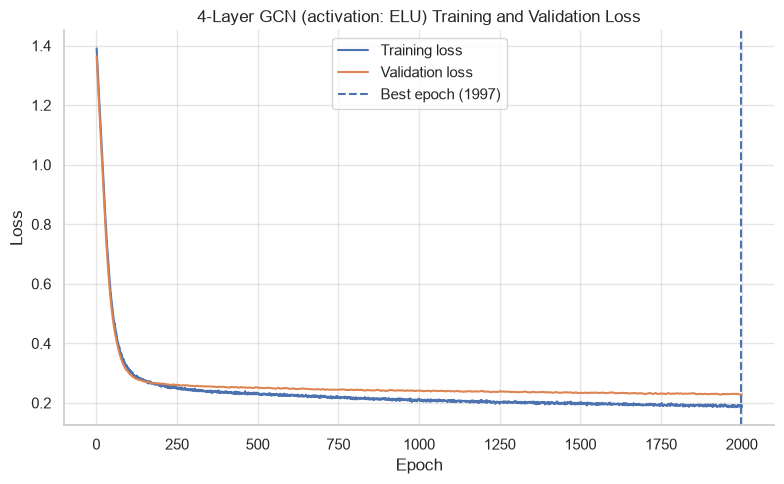

In [12]:
gcn4_loss_fig, _ = plot_training_validation_loss(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (activation: ELU) Training and Validation Loss",
)

plt.show()

In [13]:
gcn4_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_elu_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 4-Layer GCN (weight_decay=5e-5)

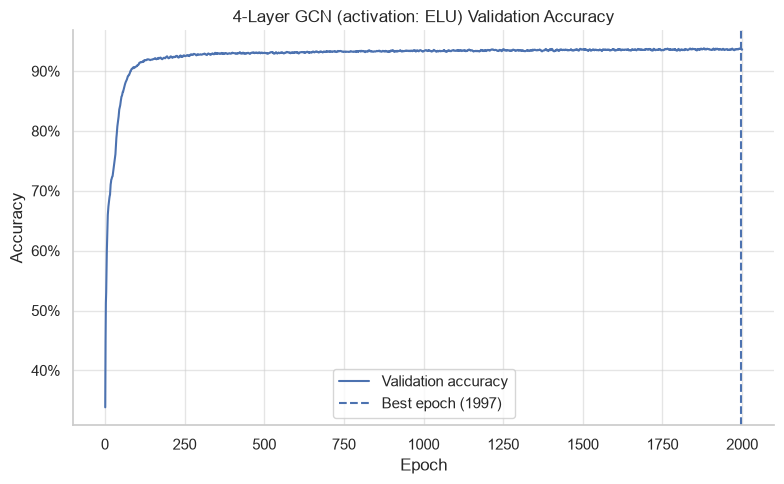

In [14]:
gcn4_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (activation: ELU) Validation Accuracy",
)

plt.show()

In [15]:
gcn4_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_elu_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 4-Layer GCN (weight_decay=5e-5) Candidate Results

In [16]:
# save 4-Layer GCN (activation: ELU) experiment results
gcn4_results = {
    "model": "GCN",
    "experiment": "activation",
    "activation": "ELU",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_055,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY_5E5,
    "best_epoch": gcn4_result["best_epoch"],
    "best_val_loss": gcn4_result["best_val_loss"],
    "training_seconds": gcn4_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn4_metrics,
    "history": gcn4_result["history"],
}

with (
    RESULTS_DIR / "gcn_elu.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_result["best_state"],
    CHECKPOINTS_DIR / "gcn_elu.pt",
)

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate the 4-Layer GCN (activation: L-ReLU) network

In [6]:
gcn4_lrelu_model = GCNNetwork4LayerLReLU(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_055,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN (activation: L-ReLU)

In [7]:
# optimiser
gcn4_lrelu_optimizer = torch.optim.Adam(
    gcn4_lrelu_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY_5E5,
)

#### Evaluate 4-Layer GCN (activation: L-ReLU) Candidate

In [8]:
# perform training and validation of the 4-Layer GCN (activation: L-ReLU)

gcn4_result = train_gcn_model(
    model=gcn4_lrelu_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    train_mask=data.train_mask,
    val_mask=data.val_mask,
    criterion=CRITERION,
    optimizer=gcn4_lrelu_optimizer,
    epochs=EPOCHS_2K,
    print_every=100,
)

> Training GCN
Epoch [   1/2000] Train Loss: 1.38755 | Val Loss: 1.38262 | Val Acc: 30.08%
Epoch [ 100/2000] Train Loss: 0.33994 | Val Loss: 0.30552 | Val Acc: 90.57%
Epoch [ 200/2000] Train Loss: 0.24538 | Val Loss: 0.24529 | Val Acc: 92.95%
Epoch [ 300/2000] Train Loss: 0.22781 | Val Loss: 0.23292 | Val Acc: 93.28%
Epoch [ 400/2000] Train Loss: 0.20483 | Val Loss: 0.22213 | Val Acc: 93.66%
Epoch [ 500/2000] Train Loss: 0.19120 | Val Loss: 0.21413 | Val Acc: 93.81%
Epoch [ 600/2000] Train Loss: 0.17782 | Val Loss: 0.20746 | Val Acc: 94.15%
Epoch [ 700/2000] Train Loss: 0.17097 | Val Loss: 0.20458 | Val Acc: 94.33%
Epoch [ 800/2000] Train Loss: 0.16256 | Val Loss: 0.20134 | Val Acc: 94.35%
Epoch [ 900/2000] Train Loss: 0.15495 | Val Loss: 0.19740 | Val Acc: 94.53%
Epoch [1000/2000] Train Loss: 0.15252 | Val Loss: 0.19722 | Val Acc: 94.75%
Epoch [1100/2000] Train Loss: 0.14530 | Val Loss: 0.19564 | Val Acc: 94.86%
Epoch [1200/2000] Train Loss: 0.14163 | Val Loss: 0.19310 | Val Acc: 94.9

Restore best result for 4-Layer GCN (activation: L-ReLU) evaluation

In [9]:
# check that a best state exists
if gcn4_result["best_state"] is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

# restore the checkpoint with the lowest validation loss
gcn4_lrelu_model.load_state_dict(
    gcn4_result["best_state"]
)

gcn4_lrelu_model.eval()

# forward pass at the selected checkpoint
with torch.inference_mode():
    gcn4_logits = gcn4_lrelu_model(
        data.x,
        data.edge_index,
    )

# calculate validation metrics
gcn4_metrics = classification_metrics(
    logits=gcn4_logits,
    labels=data.y,
    mask=data.val_mask,
)

Print 4-Layer GCN (activation: L-ReLU) evaluation metrics


In [10]:
# print compact result summary
print(
    f"Best epoch:      {gcn4_result['best_epoch']}\n"
    f"Validation loss: {gcn4_result['best_val_loss']:.5f}\n"
    f"Accuracy:        {gcn4_metrics['accuracy']:.4f}\n"
    f"Macro precision: {gcn4_metrics['macro_precision']:.4f}\n"
    f"Macro recall:    {gcn4_metrics['macro_recall']:.4f}\n"
    f"Macro F1:        {gcn4_metrics['macro_f1']:.4f}\n"
    f"Macro AUROC:     {gcn4_metrics['macro_auroc']:.4f}"
)

Best epoch:      1367
Validation loss: 0.19191
Accuracy:        0.9497
Macro precision: 0.9486
Macro recall:    0.9461
Macro F1:        0.9473
Macro AUROC:     0.9915


In [11]:
# print per-class metrics
print("\nPer-class validation metrics")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:16} "
        f"P={gcn4_metrics['precision'][i]:.4f}  "
        f"R={gcn4_metrics['recall'][i]:.4f}  "
        f"F1={gcn4_metrics['f1'][i]:.4f}  "
        f"n={gcn4_metrics['support'][i]}"
    )


Per-class validation metrics
Television show  P=0.9487  R=0.9538  F1=0.9512  n=1299
Government       P=0.9507  R=0.9520  F1=0.9513  n=1376
Company          P=0.9552  R=0.9610  F1=0.9581  n=1153
Politician       P=0.9400  R=0.9174  F1=0.9286  n=666


Visualise Validation Loss for the 4-Layer GCN (activation: L-ReLU)

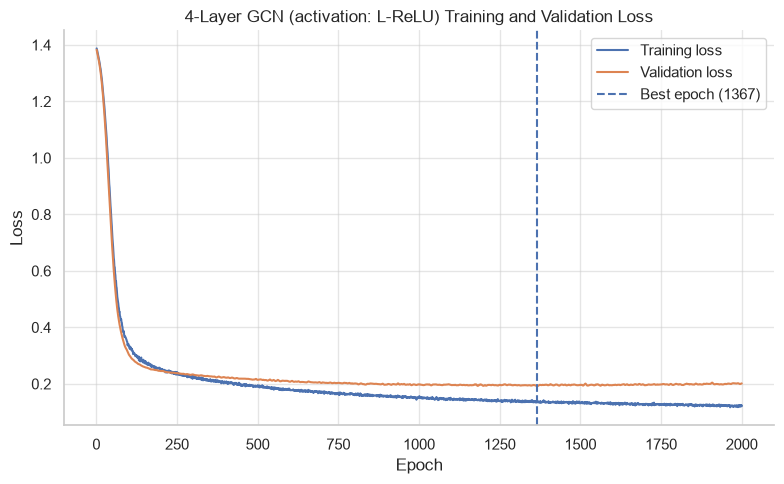

In [12]:
gcn4_loss_fig, _ = plot_training_validation_loss(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (activation: L-ReLU) Training and Validation Loss",
)

plt.show()

In [13]:
gcn4_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_lrelu_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Visualise Validation Accuracy for the 4-Layer GCN (weight_decay=5e-5)

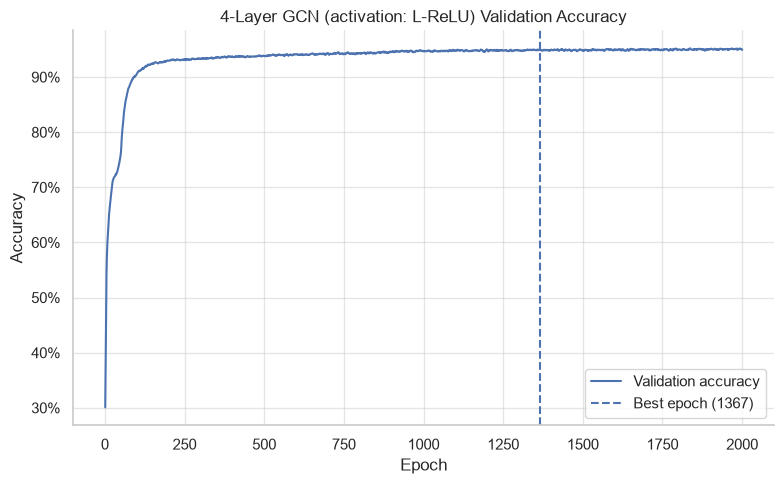

In [14]:
gcn4_accuracy_fig, _ = plot_training_validation_accuracy(
    history=gcn4_result["history"],
    best_epoch=gcn4_result["best_epoch"],
    title="4-Layer GCN (activation: L-ReLU) Validation Accuracy",
)

plt.show()

In [15]:
gcn4_accuracy_fig.savefig(
    FIGURES_DIR
    / "gcn_lrelu_validation_accuracy_2000e.png",
    dpi=200,
    bbox_inches="tight",
)

Save the 4-Layer GCN (weight_decay=5e-5) Candidate Results

In [16]:
# save 4-Layer GCN (activation: L-ReLU) experiment results
gcn4_results = {
    "model": "GCN",
    "experiment": "activation",
    "activation": "LeakyReLU",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_055,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY_5E5,
    "best_epoch": gcn4_result["best_epoch"],
    "best_val_loss": gcn4_result["best_val_loss"],
    "training_seconds": gcn4_result["elapsed"],
    "device": str(device),
    "validation_metrics": gcn4_metrics,
    "history": gcn4_result["history"],
}

with (
    RESULTS_DIR / "gcn_lrelu.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_result["best_state"],
    CHECKPOINTS_DIR / "gcn_lrelu.pt",
)

The 4-layer GCN performance metrics did not change significantly with the use of either<br>
ELU or Leaky ReLU activation functions.<br>
Therefore, ReLU is retained as the established activation.

#### 'Frozen' GCN Model:

Selected Model: mlp_wd5e5.pt

4 layers, ReLU, Adam<br>
dropout = 0.55<br>
weight_decay = 5e-5<br>
64 hidden channels<br>
learning_rate = 1e-3<br>

checkpoint - minimum validation cross-entropy: epoch 1367